# Базовые понятия: словарь серии от простого к сложному

Этот ноутбук — справочник ко всем остальным: `cdma_sim`, `ldpc_sim`, `turbo_sim`, `lte_sim`, `ofdm_sim`, `lora_sim`, `ocusync_sim`, `transforms_sim`, `otfs_sim`, `zak_sim`, `afdm_sim`, `ocdm_sim`, `otsm_sim`. Термины собраны из них и разложены по 12 уровням: каждый следующий опирается на предыдущие. Каждый уровень — короткие определения с формулами и ссылками «где встречается», затем ячейка, которая **проверяет** определение числом или картинкой: теория против моделирования.

| уровень | о чём | ключевые слова |
|---|---|---|
| 1 | сигнал | отсчёт, дискретизация, наложение, амплитуда, фаза, I/Q, дБ |
| 2 | спектр | Фурье, полоса, СПМ, символьная скорость |
| 3 | шум и качество | AWGN, SNR, Eb/N0, BER, EVM, Шеннон |
| 4 | модуляция | символ, созвездие, QAM, код Грея, мягкое решение, LLR |
| 5 | импульсы | ISI, Найквист, RRC, глазковая диаграмма, согласованный фильтр |
| 6 | корреляция и базис | корреляция, ортогональность, базис, расширение спектра, m-последовательность, Голд, Задов–Чу |
| 7 | квадратичная фаза | мгновенная частота, чирп, dechirp, сжатие импульса |
| 8 | канал | многолучевость, разброс задержек, когерентная полоса, доплер, Рэлей, Райс |
| 9 | борьба с каналом | оценка канала, эквалайзер ZF/MMSE, разнесение, MRC |
| 10 | многочастотность | OFDM, поднесущая, CP, ICI, CFO, пик-фактор |
| 11 | кодирование | код, скорость, расстояние Хэмминга, синдром, кодовый выигрыш, итеративное декодирование |
| 12 | задержка–доплер | DD-область, функция рассеяния, дробный доплер |

В конце — алфавитный указатель «термин → уровень → ноутбуки» и рекомендуемый порядок чтения серии.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc, j0, comb
from scipy.signal import welch
from scipy.stats import rice

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
rng = np.random.default_rng(SEED)

## Примитивы: Q-функция, комплексный шум, QAM с кодом Грея, RRC-фильтр, m-последовательности, периодическая корреляция

In [3]:
Q = lambda x: 0.5 * erfc(x / np.sqrt(2))                     # хвост гауссова распределения
db = lambda x: 10 * np.log10(x)

def crandn(shape, rng):
    """комплексный гауссов шум с единичной мощностью (по ½ на I и Q)"""
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def qam_const(M):
    m = int(round(np.sqrt(M))); k = int(np.log2(m))
    pam = np.empty(m); pam[np.arange(m) ^ (np.arange(m) >> 1)] = 2 * np.arange(m) - m + 1
    lab = np.arange(M); c = pam[lab >> k] + 1j * pam[lab & (m - 1)]
    return c / np.sqrt(np.mean(np.abs(c) ** 2))

def rrc(beta, sps, span):
    """корень из приподнятого косинуса, единичная энергия"""
    tt = np.arange(-span * sps, span * sps + 1) / sps; h = np.empty_like(tt)
    for i, x in enumerate(tt):
        if abs(x) < 1e-12: h[i] = 1 - beta + 4 * beta / np.pi
        elif abs(abs(x) - 1 / (4 * beta)) < 1e-9:
            h[i] = beta / np.sqrt(2) * ((1 + 2 / np.pi) * np.sin(np.pi / (4 * beta)) + (1 - 2 / np.pi) * np.cos(np.pi / (4 * beta)))
        else:
            h[i] = (np.sin(np.pi * x * (1 - beta)) + 4 * beta * x * np.cos(np.pi * x * (1 + beta))) / (np.pi * x * (1 - (4 * beta * x) ** 2))
    return h / np.sqrt(np.sum(h ** 2))

def mseq(taps, n):
    """m-последовательность из регистра сдвига с обратной связью"""
    st = [1] * n; out = []
    for _ in range(2 ** n - 1):
        out.append(st[-1]); fb = 0
        for tp in taps: fb ^= st[tp - 1]
        st = [fb] + st[:-1]
    return 1 - 2 * np.array(out)                                  # 0/1 → +1/−1

def pcorr(a, b):
    """периодическая взаимная корреляция по всем сдвигам (через FFT)"""
    return np.fft.ifft(np.fft.fft(a) * np.conj(np.fft.fft(b)))

print("Примитивы готовы")

Примитивы готовы


## 1. Сигнал
* **Отсчёт, частота дискретизации** $f_s$ — цифровой сигнал есть числа $x[n]=x(n/f_s)$, взятые через $1/f_s$ секунд.
* **Теорема отсчётов (Котельникова–Найквиста)** — сигнал с полосой до $B$ восстанавливается по отсчётам, если $f_s>2B$. Частота $f_s/2$ — **частота Найквиста**.
* **Наложение (алиасинг)** — частота выше $f_s/2$ после дискретизации неотличима от $|f-kf_s|$: 700 Гц при $f_s=1000$ Гц выглядит как 300 Гц. Поэтому перед АЦП ставят фильтр.
* **Амплитуда, фаза, частота** — в $A\cos(2\pi ft+\varphi)$. **Частота — это скорость изменения фазы**: $f=\frac1{2\pi}\frac{d\varphi}{dt}$. Отсюда «мгновенная частота» (уровень 7) и сдвиг частоты как набег фазы (CFO, уровень 10).
* **Несущая и комплексная огибающая (I/Q)** — радиосигнал $\mathrm{Re}\{s(t)e^{j2\pi f_ct}\}$ на несущей $f_c$ полностью описывается комплексным $s(t)=I(t)+jQ(t)=A(t)e^{j\varphi(t)}$. Все ноутбуки серии работают с $s(t)$ — «в основной полосе», без несущей. I и Q — две проекции вектора, вращающегося на плоскости.
* **Мощность и энергия** — $P=\overline{|s|^2}$, энергия $E=\sum|s|^2$ (на символ — $E_s$, на бит — $E_b$).
* **Децибел** — $10\lg(P_1/P_2)$ для мощностей и $20\lg(A_1/A_2)$ для амплитуд. ×2 по мощности = 3 дБ, ×10 = 10 дБ. **дБм** — мощность относительно 1 мВт. Децибелы превращают произведения (усиления, потери) в суммы — на этом построен бюджет линии (`ocusync_sim`).

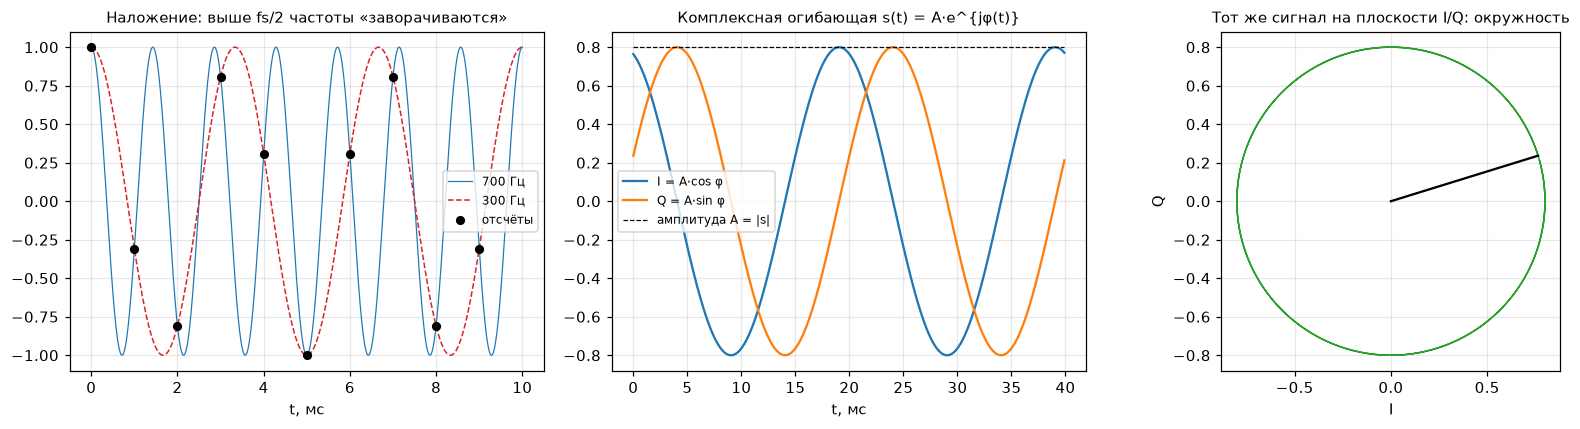

Наложение: тон 700 Гц, fs = 1000 Гц → пик FFT на 300 Гц (теория |f − fs| = 300 Гц)
Частота = скорость изменения фазы: dφ/dt / 2π = 50.00 Гц (задано 50)
Децибелы: мощность ×2 → +3.01 дБ, ×10 → +10 дБ, ×1000 → +30 дБ; амплитуда ×2 → +6.02 дБ (мощность ×4)
дБм — мощность относительно 1 мВт: 1 мВт = 0 дБм, 1 Вт = 30 дБм, 100 мВт (Wi-Fi) = 20 дБм, 1 пВт = −90 дБм


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
# дискретизация и наложение: тон 700 Гц при fs = 1000 Гц неотличим от 300 Гц
fs, f_true = 1000, 700
tf = np.linspace(0, 0.01, 2000); ts = np.arange(0, 0.01, 1 / fs)
ax[0].plot(tf * 1e3, np.cos(2 * np.pi * f_true * tf), "C0", lw=0.8, label="700 Гц")
ax[0].plot(tf * 1e3, np.cos(2 * np.pi * (fs - f_true) * tf), "C3--", lw=1, label="300 Гц")
ax[0].plot(ts * 1e3, np.cos(2 * np.pi * f_true * ts), "ko", ms=5, label="отсчёты")
ax[0].set_xlabel("t, мс"); ax[0].legend(fontsize=8); ax[0].set_title("Наложение: выше fs/2 частоты «заворачиваются»", fontsize=10)
xs = np.cos(2 * np.pi * f_true * np.arange(1000) / fs)
f_meas = np.argmax(np.abs(np.fft.rfft(xs))) * fs / 1000

# комплексная огибающая: I и Q — две проекции вращающегося вектора
t = np.arange(0, 0.04, 1e-4); f0 = 50
s = 0.8 * np.exp(1j * (2 * np.pi * f0 * t + 0.3))
ax[1].plot(t * 1e3, s.real, "C0", label="I = A·cos φ"); ax[1].plot(t * 1e3, s.imag, "C1", label="Q = A·sin φ")
ax[1].plot(t * 1e3, np.abs(s), "k--", lw=0.8, label="амплитуда A = |s|")
ax[1].set_xlabel("t, мс"); ax[1].legend(fontsize=8); ax[1].set_title("Комплексная огибающая s(t) = A·e^{jφ(t)}", fontsize=10)
ax[2].plot(s.real, s.imag, "C2", lw=1); ax[2].plot([0, s.real[0]], [0, s.imag[0]], "k-", lw=1.5)
ax[2].set_aspect("equal"); ax[2].set_xlabel("I"); ax[2].set_ylabel("Q"); ax[2].set_title("Тот же сигнал на плоскости I/Q: окружность", fontsize=10)
plt.tight_layout(); plt.show()

f_from_phase = np.mean(np.diff(np.unwrap(np.angle(s)))) / (2 * np.pi * 1e-4)
print(f"Наложение: тон {f_true} Гц, fs = {fs} Гц → пик FFT на {f_meas:.0f} Гц (теория |f − fs| = {abs(f_true - fs)} Гц)")
print(f"Частота = скорость изменения фазы: dφ/dt / 2π = {f_from_phase:.2f} Гц (задано {f0})")
print("Децибелы: мощность ×2 → {:+.2f} дБ, ×10 → {:+.0f} дБ, ×1000 → {:+.0f} дБ; амплитуда ×2 → {:+.2f} дБ (мощность ×4)".format(db(2), db(10), db(1000), 20 * np.log10(2)))
print("дБм — мощность относительно 1 мВт: 1 мВт = 0 дБм, 1 Вт = 30 дБм, 100 мВт (Wi-Fi) = 20 дБм, 1 пВт = −90 дБм")

## 2. Спектр и полоса
* **Спектр, преобразование Фурье** — разложение сигнала на синусоиды: $X(f)=\int x(t)e^{-j2\pi ft}dt$. Его дискретная версия **DFT** считается алгоритмом **FFT** за $N\log N$. Подробно об окнах, утечке и разрешении — `transforms_sim`, раздел 1.
* **Бин** — одна частотная ячейка DFT шириной $f_s/N$.
* **Спектральная плотность мощности (СПМ, PSD)** — как мощность распределена по частоте. Для случайных данных — среднее $|X(f)|^2$ по многим кускам (метод Уэлча).
* **Полоса** — ширина занимаемых частот. Определений несколько: по нулям, по −3 дБ, по 99 % мощности. Мерило «сколько эфира занимает передача».
* **Символьная скорость** $R$ (бод) — сколько символов в секунду. Полоса не может быть меньше $R$ (уровень 5): быстрее менять сигнал — значит шире спектр.
* **Внеполосное излучение, ACLR, спектральная маска** — сколько мощности попадает к соседям. Прямоугольные символы дают спектр $\mathrm{sinc}^2$, спадающий как $1/f^2$: 99 % мощности занимают ~19 R. Сглаженный импульс RRC укладывает 99 % в 1.17 R, а всю мощность — в $(1+\beta)R$ (`ofdm_sim`, раздел 2).

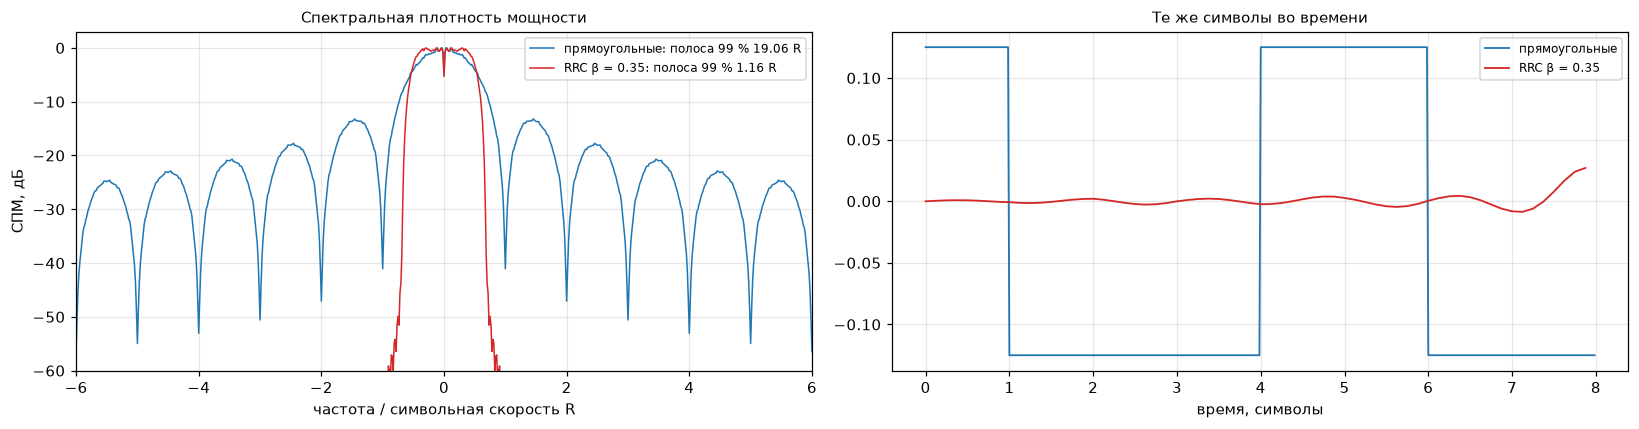

Полоса, содержащая 99 % мощности: прямоугольные 19.1 R (теория ∫sinc²: 19.2 R), RRC 1.16 R (теория 1.17 R; вся полоса RRC — (1+β)·R = 1.35 R)


In [4]:
# спектр и полоса: прямоугольные символы против импульсов RRC
NS = 20000
sym = 1 - 2 * rng.integers(0, 2, NS).astype(float)
def shaped(pulse, sps):
    up = np.zeros(NS * sps); up[::sps] = sym; return np.convolve(up, pulse)[:NS * sps], sps
x_rect = shaped(np.ones(64) / 8, 64)                            # 64 отсч./символ: спектр sinc² нужно видеть до ±32R
x_rrc = shaped(rrc(0.35, 8, 10), 8)
def occ_bw(xs, frac=0.99):
    x, sps = xs
    f, p = welch(x, fs=sps, nperseg=64 * sps, return_onesided=False); i = np.argsort(f); f, p = f[i], p[i]
    c = np.cumsum(p) / p.sum(); lo, hi = f[np.searchsorted(c, (1 - frac) / 2)], f[np.searchsorted(c, 1 - (1 - frac) / 2)]
    return f, p / p.max(), hi - lo
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
res = {}
for (nm, x), c in zip((("прямоугольные", x_rect), ("RRC β = 0.35", x_rrc)), ("C0", "C3")):
    f, p, bw = occ_bw(x); res[nm] = bw
    ax[0].plot(f, 10 * np.log10(p + 1e-12), c, lw=1, label=f"{nm}: полоса 99 % {bw:.2f} R")
    ax[1].plot(np.arange(8 * x[1]) / x[1], x[0][:8 * x[1]], c, lw=1.2, label=nm)
ax[0].set_xlim(-6, 6); ax[0].set_ylim(-60, 3); ax[0].set_xlabel("частота / символьная скорость R"); ax[0].set_ylabel("СПМ, дБ"); ax[0].legend(fontsize=8)
ax[0].set_title("Спектральная плотность мощности", fontsize=10)
ax[1].set_xlabel("время, символы"); ax[1].legend(fontsize=8); ax[1].set_title("Те же символы во времени", fontsize=10)
plt.tight_layout(); plt.show()
ff = np.linspace(-200, 200, 400001); ps = np.sinc(ff) ** 2; cs = np.cumsum(ps) / ps.sum()
bw_th = ff[np.searchsorted(cs, 0.995)] - ff[np.searchsorted(cs, 0.005)]
fr = np.linspace(-1, 1, 200001); be = 0.35; af = np.abs(fr)
prc = np.where(af <= (1 - be) / 2, 1.0, np.where(af <= (1 + be) / 2, 0.5 * (1 + np.cos(np.pi / be * (af - (1 - be) / 2))), 0.0))
cr = np.cumsum(prc) / prc.sum(); bw_rc = fr[np.searchsorted(cr, 0.995)] - fr[np.searchsorted(cr, 0.005)]
print(f"Полоса, содержащая 99 % мощности: прямоугольные {res[list(res)[0]]:.1f} R (теория ∫sinc²: {bw_th:.1f} R), RRC {res[list(res)[1]]:.2f} R (теория {bw_rc:.2f} R; вся полоса RRC — (1+β)·R = 1.35 R)")

## 3. Шум и качество связи
* **AWGN** (additive white Gaussian noise) — аддитивный белый гауссов шум: прибавляется к сигналу, одинаков на всех частотах, распределён по Гауссу. Базовая модель канала, «идеальный» случай: $y=x+n$.
* **Тепловой шум** — $kT=-174$ дБм/Гц при 290 K; в полосе $B$ это $kTB$. **Коэффициент шума** (NF) приёмника добавляет несколько дБ.
* **SNR** — отношение мощностей сигнала и шума в полосе сигнала. **$E_s/N_0$** — энергия символа к спектральной плотности шума. **$E_b/N_0$** — то же на бит данных: $E_b/N_0=\frac{E_s/N_0}{\log_2M\cdot R_{код}}$. Именно $E_b/N_0$ позволяет честно сравнивать системы с разной модуляцией и кодом (все кривые BER в `ldpc_sim`, `turbo_sim`).
* **BER, SER, FER/BLER** — вероятность ошибки бита, символа, кадра (блока). Для BPSK в AWGN $\mathrm{BER}=Q(\sqrt{2E_b/N_0})$, где $Q$ — хвост гауссова распределения.
* **EVM** (error vector magnitude) — среднеквадратичное отклонение принятых точек созвездия от идеальных, в % или дБ. В AWGN $\mathrm{EVM}=1/\sqrt{\mathrm{SNR}}$. Удобен для оценки искажений тракта (`ofdm_sim`, разделы 4–5).
* **Ёмкость Шеннона** — $C=B\log_2(1+\mathrm{SNR})$: больше передать без ошибок нельзя. **Спектральная эффективность** $\eta=C/B$ бит/с/Гц. Минимальный $E_b/N_0=(2^\eta-1)/\eta$; при $\eta\to0$ это $\ln2=-1.59$ дБ — **предел Шеннона**.

Средний график — главная карта связи: точки показывают, сколько энергии на бит нужно модуляциям без кода, кривая — сколько нужно в принципе. Разрыв в ~8 дБ закрывают коды (уровень 11).

Тепловой шум kT при 290 K: -174.0 дБм/Гц; в полосе 20 МГц: -101.0 дБм; с коэффициентом шума приёмника 7 дБ: -94.0 дБм


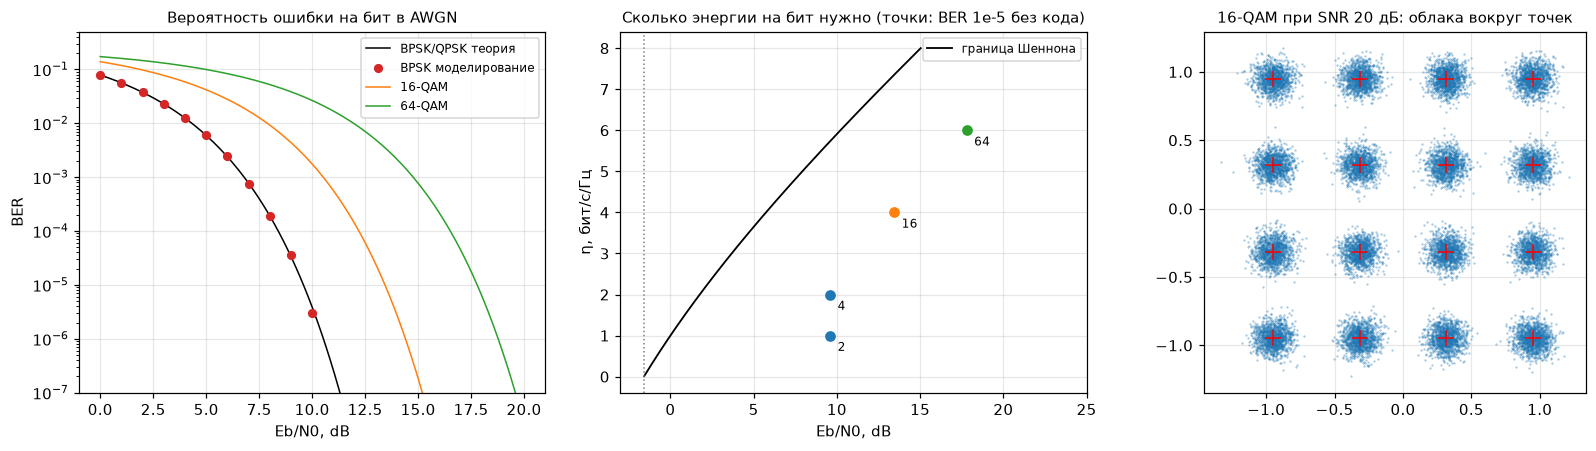

  BPSK, Eb/N0 = 4 дБ: BER моделирование 1.25e-02, теория 1.25e-02
  BPSK, Eb/N0 = 8 дБ: BER моделирование 1.87e-04, теория 1.91e-04
  BPSK, Eb/N0 = 10 дБ: BER моделирование 3.00e-06, теория 3.87e-06
Предел Шеннона при η → 0: Eb/N0 = ln 2 = -1.59 дБ; для BER 1e-5 без кода нужно: BPSK 9.6 dB, QPSK 9.6 dB, 16-QAM 13.4 dB, 64-QAM 17.8 dB
  при η = 2 (QPSK) Шеннон требует 1.8 дБ — запас 7.8 дБ и есть то, что забирают турбо- и LDPC-коды
EVM 16-QAM при SNR 20 дБ: -20.1 дБ = 9.9 % (теория: EVM = 1/√SNR = −20 дБ = 10 %)


In [5]:
# тепловой шум
k_B, T0 = 1.380649e-23, 290
print(f"Тепловой шум kT при 290 K: {10*np.log10(k_B*T0*1e3):.1f} дБм/Гц; в полосе 20 МГц: {10*np.log10(k_B*T0*20e6*1e3):.1f} дБм; с коэффициентом шума приёмника 7 дБ: {10*np.log10(k_B*T0*20e6*1e3)+7:.1f} дБм")

# BER BPSK: моделирование против Q(√(2Eb/N0))
ebn0 = np.arange(0, 11)
ber_sim = []
for e in ebn0:
    nb = 2_000_000; b = rng.integers(0, 2, nb); x = 1 - 2 * b
    y = x + rng.standard_normal(nb) * np.sqrt(1 / (2 * 10 ** (e / 10)))
    ber_sim.append(np.mean((y < 0) != b))
ber_qam = lambda M, g: 4 / np.log2(M) * (1 - 1 / np.sqrt(M)) * Q(np.sqrt(3 * np.log2(M) * g / (M - 1)))
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
eb = np.linspace(0, 20, 200); g = 10 ** (eb / 10)
ax[0].semilogy(eb, Q(np.sqrt(2 * g)), "k-", lw=1, label="BPSK/QPSK теория")
ax[0].semilogy(ebn0, np.maximum(ber_sim, 1e-7), "C3o", ms=5, label="BPSK моделирование")
for M, c in ((16, "C1"), (64, "C2")):
    ax[0].semilogy(eb, ber_qam(M, g), c, lw=1, label=f"{M}-QAM")
ax[0].set_ylim(1e-7, 0.5); ax[0].set_xlabel("Eb/N0, dB"); ax[0].set_ylabel("BER"); ax[0].legend(fontsize=8)
ax[0].set_title("Вероятность ошибки на бит в AWGN", fontsize=10)

# Шеннон: минимальный Eb/N0 для спектральной эффективности η
eta = np.linspace(0.01, 8, 400)
ax[1].plot(10 * np.log10((2 ** eta - 1) / eta), eta, "k-", lw=1.2, label="граница Шеннона")
ax[1].axvline(10 * np.log10(np.log(2)), color="gray", ls=":", lw=1)
need = {}
for M, bits, c in ((2, 1, "C0"), (4, 2, "C0"), (16, 4, "C1"), (64, 6, "C2")):
    f = (lambda gg: Q(np.sqrt(2 * gg))) if M <= 4 else (lambda gg, M=M: ber_qam(M, gg))
    lo, hi = 0.0, 40.0
    for _ in range(60):
        mid = (lo + hi) / 2; lo, hi = (mid, hi) if f(10 ** (mid / 10)) > 1e-5 else (lo, mid)
    need[M] = hi; ax[1].plot(hi, bits, c + "o", ms=6); ax[1].annotate(f"{M}", (hi, bits), textcoords="offset points", xytext=(5, -10), fontsize=8)
ax[1].set_xlabel("Eb/N0, dB"); ax[1].set_ylabel("η, бит/с/Гц"); ax[1].set_xlim(-3, 25); ax[1].legend(fontsize=8)
ax[1].set_title("Сколько энергии на бит нужно (точки: BER 1e-5 без кода)", fontsize=10)

# EVM и SNR
c16 = qam_const(16); lab = rng.integers(0, 16, 20000)
ys = c16[lab] + crandn(20000, rng) * 10 ** (-20 / 20)
ax[2].plot(ys.real, ys.imag, ".", ms=1, alpha=0.4); ax[2].plot(c16.real, c16.imag, "r+", ms=10)
ax[2].set_aspect("equal"); ax[2].set_title("16-QAM при SNR 20 дБ: облака вокруг точек", fontsize=10)
plt.tight_layout(); plt.show()

for e in (4, 8, 10):
    print(f"  BPSK, Eb/N0 = {e} дБ: BER моделирование {ber_sim[e]:.2e}, теория {Q(np.sqrt(2*10**(e/10))):.2e}")
print(f"Предел Шеннона при η → 0: Eb/N0 = ln 2 = {10*np.log10(np.log(2)):.2f} дБ; для BER 1e-5 без кода нужно: " + ", ".join(f"{M}-QAM {v:.1f} dB" if M > 4 else f"{'BPSK' if M == 2 else 'QPSK'} {v:.1f} dB" for M, v in need.items()))
print(f"  при η = 2 (QPSK) Шеннон требует {10*np.log10(3/2):.1f} дБ — запас {need[4]-10*np.log10(3/2):.1f} дБ и есть то, что забирают турбо- и LDPC-коды")
print(f"EVM 16-QAM при SNR 20 дБ: {10*np.log10(np.mean(np.abs(ys - c16[lab])**2)):.1f} дБ = {100*np.sqrt(np.mean(np.abs(ys - c16[lab])**2)):.1f} % (теория: EVM = 1/√SNR = −20 дБ = 10 %)")

## 4. Модуляция
* **Символ** — одно комплексное число, передаваемое за интервал $T=1/R$; несёт $\log_2M$ бит.
* **Созвездие** — набор $M$ допустимых символов на плоскости I/Q. **BPSK** ($\pm1$), **QPSK** (4 точки по кругу, 2 бита), **M-QAM** (квадратная решётка: 16-QAM — 4 бита, 64-QAM — 6 бит), **PSK** (точки на окружности). У LoRa символ — не точка, а сдвиг чирпа (**CSS**, chirp spread spectrum, `lora_sim`).
* **Код Грея** — нумерация точек, при которой ближайшие соседи отличаются одним битом. Самая частая ошибка (перепутать соседей) портит только 1 бит.
* **Жёсткое решение** — приёмник выбирает ближайшую точку и выдаёт биты. **Мягкое решение** — выдаёт ещё и уверенность.
* **LLR** (log-likelihood ratio) — $L=\ln\frac{P(b=0\mid y)}{P(b=1\mid y)}$; для BPSK в AWGN $L=2y/\sigma^2$. Знак — решение, модуль — надёжность. LLR — язык, на котором демодулятор говорит с декодером (`ldpc_sim` раздел 5, `turbo_sim`). Правый график проверяет, что это честная вероятность: $P(b=0\mid L)=1/(1+e^{-L})$.

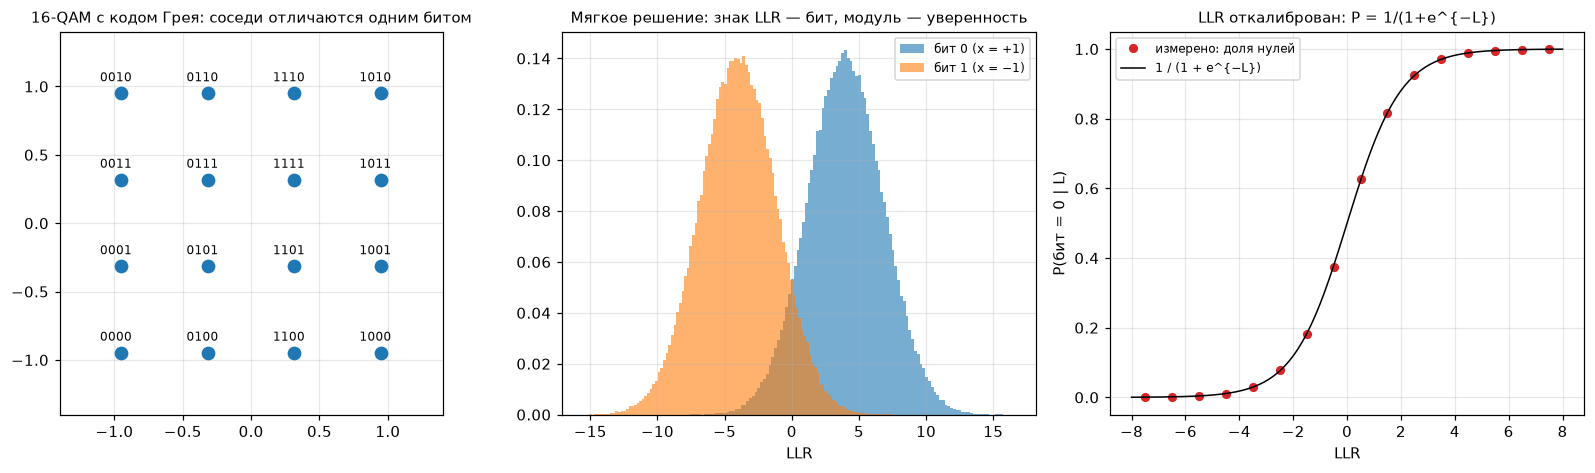

Все 24 пар ближайших соседей 16-QAM отличаются ровно одним битом: True
Калибровка LLR: max |измерено − 1/(1+e^(−L))| = 0.003
Ошибки жёсткого решения среди |L| < 1: 0.37, среди |L| > 6: 8.7e-04 — декодер должен доверять им по-разному


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
c16 = qam_const(16)
ax[0].plot(c16.real, c16.imag, "C0o", ms=8)
for i, p in enumerate(c16):
    ax[0].annotate(format(i, "04b"), (p.real, p.imag), textcoords="offset points", xytext=(-14, 8), fontsize=8)
ax[0].set_aspect("equal"); ax[0].set_xlim(-1.4, 1.4); ax[0].set_ylim(-1.4, 1.4)
ax[0].set_title("16-QAM с кодом Грея: соседи отличаются одним битом", fontsize=10)

# LLR для BPSK: L = 2y/σ²; проверяем, что это честный логарифм отношения вероятностей
sig2 = 0.5; nb = 400000; b = rng.integers(0, 2, nb); y = (1 - 2 * b) + rng.standard_normal(nb) * np.sqrt(sig2)
L = 2 * y / sig2
ax[1].hist(L[b == 0], 120, density=True, alpha=0.6, label="бит 0 (x = +1)"); ax[1].hist(L[b == 1], 120, density=True, alpha=0.6, label="бит 1 (x = −1)")
ax[1].set_xlabel("LLR"); ax[1].legend(fontsize=8); ax[1].set_title("Мягкое решение: знак LLR — бит, модуль — уверенность", fontsize=10)
edges = np.linspace(-8, 8, 17); mid = (edges[1:] + edges[:-1]) / 2
p0 = np.array([np.mean(b[(L >= lo) & (L < hi)] == 0) for lo, hi in zip(edges[:-1], edges[1:])])
ax[2].plot(mid, p0, "C3o", ms=5, label="измерено: доля нулей")
lg = np.linspace(-8, 8, 200); ax[2].plot(lg, 1 / (1 + np.exp(-lg)), "k-", lw=1, label="1 / (1 + e^{−L})")
ax[2].set_xlabel("LLR"); ax[2].set_ylabel("P(бит = 0 | L)"); ax[2].legend(fontsize=8)
ax[2].set_title("LLR откалиброван: P = 1/(1+e^{−L})", fontsize=10)
plt.tight_layout(); plt.show()

d = np.abs(c16[:, None] - c16[None]); dmin = d[d > 1e-9].min()
nbr = np.argwhere(np.abs(d - dmin) < 1e-9)
print(f"Все {len(nbr)//2} пар ближайших соседей 16-QAM отличаются ровно одним битом: {all(bin(a ^ b).count('1') == 1 for a, b in nbr)}")
print(f"Калибровка LLR: max |измерено − 1/(1+e^(−L))| = {np.nanmax(np.abs(p0 - 1/(1+np.exp(-mid)))):.3f}")
print(f"Ошибки жёсткого решения среди |L| < 1: {np.mean((L[np.abs(L)<1] < 0) != b[np.abs(L)<1]):.2f}, среди |L| > 6: {np.mean((L[np.abs(L)>6] < 0) != b[np.abs(L)>6]):.1e} — декодер должен доверять им по-разному")

## 5. Импульсы, межсимвольная помеха, согласованный фильтр
* **Формирующий импульс** $p(t)$ — форма, которой передаётся каждый символ: $s(t)=\sum_kX_kp(t-kT)$.
* **Межсимвольная помеха (ISI)** — хвосты соседних импульсов попадают в момент отсчёта текущего. Возникает от узкого канала, многолучевости (уровень 8) или плохого импульса.
* **Критерий Найквиста** — ISI нет, если суммарный импульс проходит через ноль во все моменты $kT$, $k\neq0$. Минимальная полоса такого импульса — $R/2$ с каждой стороны.
* **Приподнятый косинус (RC), корень из него (RRC), скругление** $\beta$ — RC удовлетворяет Найквисту с полосой $(1+\beta)R/2$. Его делят поровну: RRC на передатчике и RRC на приёмнике.
* **Глазковая диаграмма** — наложение многих отрезков сигнала длиной 2 символа. Открытый «глаз» в момент отсчёта — нет ISI; закрытый — есть.
* **Согласованный фильтр** — фильтр, импульсная характеристика которого — отражённый во времени ожидаемый импульс, $h(t)=p^*(-t)$. Максимизирует SNR в момент отсчёта: $\mathrm{SNR}=E/\sigma^2$ (неравенство Коши–Буняковского). Корреляция с эталоном (уровень 6) — это и есть согласованный фильтр. Он стоит в любом приёмнике серии: коррелятор CDMA, dechirp LoRa, FFT в OFDM (согласованный фильтр сразу для всех поднесущих).

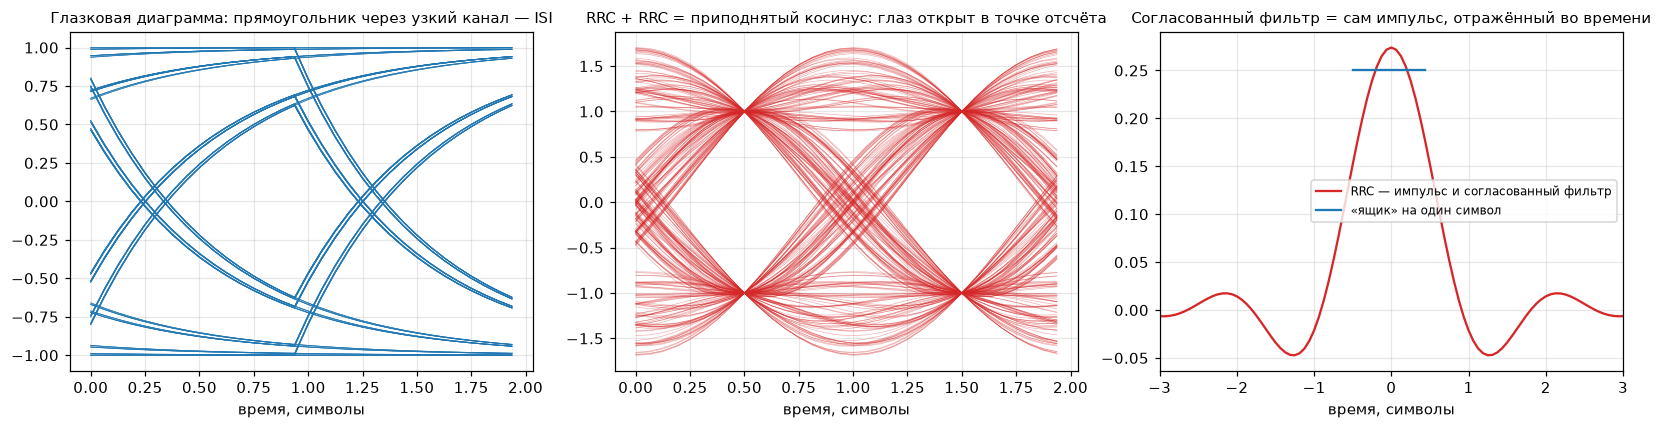

Приподнятый косинус в моменты отсчёта соседних символов: max |p(kT)|/p(0) = 3.0e-04 (усечение фильтра до ±8 символов)
Согласованный фильтр: SNR на выходе 0.10 дБ, теория E/σ² = 0.00 дБ; «ящик» даёт -0.72 дБ — на 0.72 дБ хуже (неравенство Коши–Буняковского)


In [7]:
SPS, NS = 16, 3000
sym = 1 - 2 * rng.integers(0, 2, NS).astype(float)
up = np.zeros(NS * SPS); up[::SPS] = sym
h_rrc = rrc(0.35, SPS, 8)
rc = np.convolve(np.convolve(up, h_rrc), h_rrc)                 # RRC на передаче + RRC на приёме = приподнятый косинус
d_rc = len(h_rrc) - 1
# прямоугольный импульс через фильтр-канал с узкой полосой (RC-цепь)
x_rect = np.convolve(up, np.ones(SPS))[:NS * SPS]
a_lp = np.exp(-1 / (0.6 * SPS)); y_rect = np.zeros_like(x_rect); acc = 0.0
for i, v in enumerate(x_rect):
    acc = a_lp * acc + (1 - a_lp) * v; y_rect[i] = acc
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k in range(50, 400):
    ax[0].plot(np.arange(2 * SPS) / SPS, y_rect[k * SPS:(k + 2) * SPS], "C0", lw=0.4, alpha=0.4)
    ax[1].plot(np.arange(2 * SPS) / SPS, rc[d_rc + k * SPS - SPS // 2:d_rc + k * SPS - SPS // 2 + 2 * SPS], "C3", lw=0.4, alpha=0.4)
ax[0].set_title("Глазковая диаграмма: прямоугольник через узкий канал — ISI", fontsize=10)
ax[1].set_title("RRC + RRC = приподнятый косинус: глаз открыт в точке отсчёта", fontsize=10)
for a_ in ax[:2]: a_.set_xlabel("время, символы")
# согласованный фильтр: импульс RRC в белом шуме
sig2 = 1.0; E = np.sum(h_rrc ** 2)
snr_mf = E / sig2
box = np.ones(SPS) / np.sqrt(SPS); ctr = len(h_rrc) // 2
snr_box = (h_rrc[ctr - SPS // 2:ctr + SPS // 2] @ box) ** 2 / sig2
trials = 20000; nz = rng.standard_normal((trials, len(h_rrc))) * np.sqrt(sig2)
out_mf = (h_rrc + nz) @ h_rrc
snr_mf_meas = np.mean(out_mf) ** 2 / np.var(out_mf)
ax[2].plot(np.arange(len(h_rrc)) / SPS - 8, h_rrc, "C3", label="RRC — импульс и согласованный фильтр")
ax[2].plot((np.arange(SPS) - SPS // 2) / SPS, box, "C0", label="«ящик» на один символ")
ax[2].set_xlim(-3, 3); ax[2].set_xlabel("время, символы"); ax[2].legend(fontsize=8)
ax[2].set_title("Согласованный фильтр = сам импульс, отражённый во времени", fontsize=10)
plt.tight_layout(); plt.show()

rcp = np.convolve(h_rrc, h_rrc); c0 = len(rcp) // 2
isi = np.abs(rcp[c0 + SPS * np.r_[-6:0, 1:7]]).max() / rcp[c0]
print(f"Приподнятый косинус в моменты отсчёта соседних символов: max |p(kT)|/p(0) = {isi:.1e} (усечение фильтра до ±8 символов)")
print(f"Согласованный фильтр: SNR на выходе {db(snr_mf_meas):.2f} дБ, теория E/σ² = {db(snr_mf):.2f} дБ; «ящик» даёт {db(snr_box):.2f} дБ — на {db(snr_mf)-db(snr_box):.2f} дБ хуже (неравенство Коши–Буняковского)")

## 6. Корреляция, ортогональность, базис
* **Скалярное произведение и корреляция** — $\langle x,y\rangle=\sum_nx[n]y^*[n]$: насколько сигналы похожи. **Взаимная корреляция** $R_{xy}[k]=\sum_nx[n]y^*[n-k]$ — похожесть при сдвиге $k$. **Автокорреляция** — сигнала с самим собой. **Периодическая** — сдвиг по кругу (как после CP или в повторяющейся преамбуле).
* **Ортогональность** — $\langle x,y\rangle=0$: сигналы не мешают друг другу при приёме коррелятором. Поднесущие OFDM, коды Уолша, чирпы OCDM — ортогональные наборы.
* **Базис, ортонормированный базис** — набор ортогональных функций единичной энергии, по которым раскладывается любой сигнал: $x=\sum_k\langle x,\psi_k\rangle\psi_k$ (**проекции**). **Парсеваль**: энергия сохраняется. Каждая форма сигнала серии — выбор базиса (`transforms_sim`).
* **Расширение спектра (DSSS), чип** — каждый бит умножается на быструю последовательность из $N$ **чипов**. Приёмник коррелирует с той же последовательностью (**свёртка**, despreading). Сигнал складывается когерентно, шум — нет: **выигрыш обработки** $10\lg N$ дБ (`cdma_sim`).
* **m-последовательность** — выход регистра сдвига с обратной связью максимальной длины $2^n-1$. Периодическая автокорреляция идеальна: $N$ в нуле и $-1$ везде. Синхронизация CDMA, GPS.
* **Коды Голда** — сумма двух «предпочтительных» m-последовательностей. Взаимная корреляция ограничена тремя значениями ($\pm17$ при $n=7$), поэтому много абонентов могут работать в одной полосе. У произвольной пары — до 41.
* **Задов–Чу (ZC), CAZAC** — $e^{-j\pi un(n+1)/N}$: постоянная амплитуда (Constant Amplitude) и нулевая периодическая автокорреляция вне пика (Zero AutoCorrelation). Преамбулы LTE/NR, DroneID (`ocusync_sim`). Это дискретный чирп (уровень 7).
* **Синхронизация, захват** — поиск сдвига, при котором корреляция с известной последовательностью (**преамбулой**) максимальна.

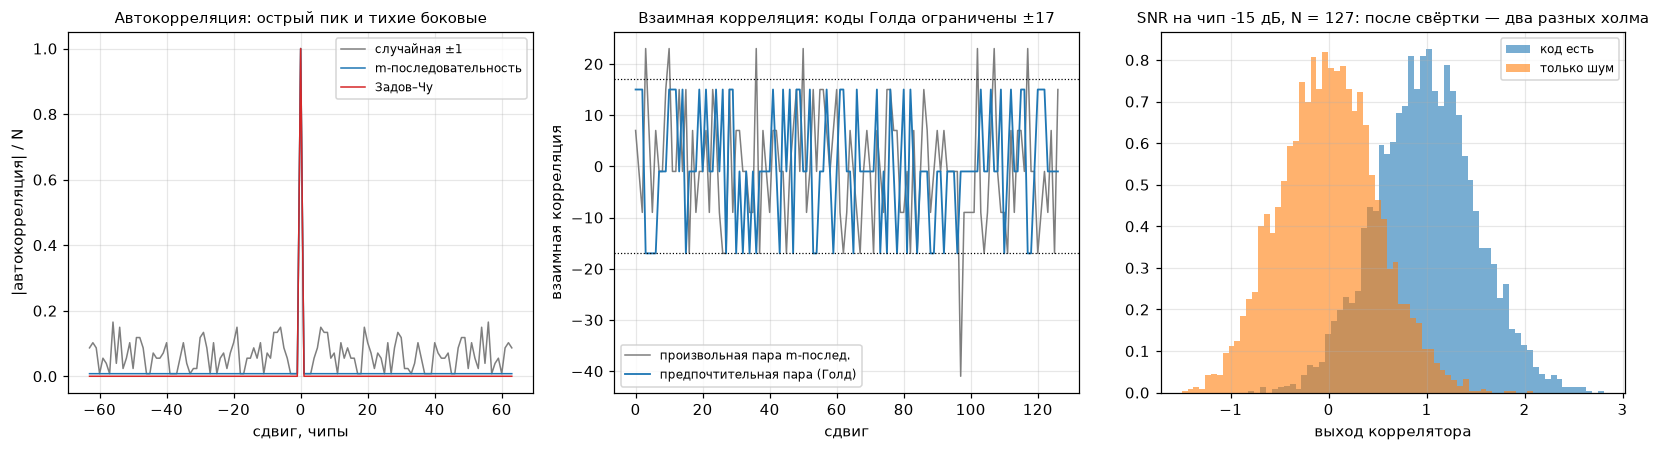

Периодическая автокорреляция m-послед. вне пика: [-1] (теория −1); |ZC| вне пика: 4.7e-12; |ZC[n]| = 1.000…1.000 (постоянная амплитуда: CAZAC)
Взаимная корреляция: пара Голда [-17, -1, 15] (теория −1, −17, 15); произвольная пара до 41
Выигрыш обработки: SNR на чип -15 дБ → после корреляции 5.8 дБ (теория -15 + 10·lg 127 = 6.0 дБ)
Базис: 8 функций Уолша ортогональны — Wᵀ·W = 8·I: True; любой вектор = Σ проекций: ошибка 2.2e-16


In [8]:
u = mseq([7, 3], 7); v = mseq([7, 3, 2, 1], 7); w = mseq([7, 6, 5, 4], 7)
Nn = len(u)
zc = np.exp(-1j * np.pi * 5 * np.arange(Nn) * (np.arange(Nn) + 1) / Nn)      # Задов–Чу, корень 5, длина 127 (простая)
rnd = 1 - 2 * rng.integers(0, 2, Nn)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for x_, nm, c in ((rnd, "случайная ±1", "C7"), (u, "m-последовательность", "C0"), (zc, "Задов–Чу", "C3")):
    r = np.abs(pcorr(x_, x_)) / Nn
    ax[0].plot(np.arange(-63, 64), np.roll(r, 63), c, lw=1, label=nm)
ax[0].set_xlabel("сдвиг, чипы"); ax[0].set_ylabel("|автокорреляция| / N"); ax[0].legend(fontsize=8)
ax[0].set_title("Автокорреляция: острый пик и тихие боковые", fontsize=10)
ccg = pcorr(u, v).real; ccx = pcorr(u, w).real
ax[1].plot(ccx, "C7", lw=1, label="произвольная пара m-послед."); ax[1].plot(ccg, "C0", lw=1.2, label="предпочтительная пара (Голд)")
ax[1].axhline(17, color="k", ls=":", lw=0.8); ax[1].axhline(-17, color="k", ls=":", lw=0.8)
ax[1].set_xlabel("сдвиг"); ax[1].set_ylabel("взаимная корреляция"); ax[1].legend(fontsize=8)
ax[1].set_title("Взаимная корреляция: коды Голда ограничены ±17", fontsize=10)
# выигрыш обработки: сигнал −15 дБ на чип вытаскивается корреляцией
SNR_CHIP = -15; trials = 4000
rx = u[None] + rng.standard_normal((trials, Nn)) * 10 ** (-SNR_CHIP / 20)
stat = rx @ u / Nn
ax[2].hist(stat, 60, density=True, alpha=0.6, label="код есть")
stat0 = (rng.standard_normal((trials, Nn)) * 10 ** (-SNR_CHIP / 20)) @ u / Nn
ax[2].hist(stat0, 60, density=True, alpha=0.6, label="только шум")
ax[2].set_xlabel("выход коррелятора"); ax[2].legend(fontsize=8)
ax[2].set_title(f"SNR на чип {SNR_CHIP} дБ, N = {Nn}: после свёртки — два разных холма", fontsize=10)
plt.tight_layout(); plt.show()

print(f"Периодическая автокорреляция m-послед. вне пика: {sorted(set(np.round(pcorr(u, u).real[1:]).astype(int).tolist()))} (теория −1); |ZC| вне пика: {np.abs(pcorr(zc, zc)[1:]).max():.1e}; |ZC[n]| = {np.abs(zc).min():.3f}…{np.abs(zc).max():.3f} (постоянная амплитуда: CAZAC)")
print(f"Взаимная корреляция: пара Голда {sorted(set(np.round(ccg).astype(int).tolist()))} (теория −1, −17, 15); произвольная пара до {np.abs(ccx).max():.0f}")
print(f"Выигрыш обработки: SNR на чип {SNR_CHIP} дБ → после корреляции {db(np.mean(stat)**2/np.var(stat)):.1f} дБ (теория {SNR_CHIP} + 10·lg {Nn} = {SNR_CHIP + db(Nn):.1f} дБ)")
Wh = np.array([[1]])
for _ in range(3): Wh = np.block([[Wh, Wh], [Wh, -Wh]])
print(f"Базис: 8 функций Уолша ортогональны — Wᵀ·W = 8·I: {np.array_equal(Wh.T @ Wh, 8 * np.eye(8))}; любой вектор = Σ проекций: ошибка {np.abs(Wh.T @ (Wh @ (z := rng.standard_normal(8))) / 8 - z).max():.1e}")

## 7. Квадратичная фаза и чирпы
* **Мгновенная частота** — $f(t)=\frac1{2\pi}\frac{d\varphi}{dt}$ (уровень 1) для сигнала, частота которого меняется.
* **Квадратичная фаза, ЛЧМ, чирп** — $\varphi(t)=\pi\mu t^2$ даёт **линейно меняющуюся частоту** $f(t)=\mu t$: «свист» от $-B/2$ до $B/2$ за время $T$, $\mu=B/T$. Чирпы — основа LoRa (`lora_sim`), радаров, OCDM и AFDM (`ocdm_sim`, `afdm_sim`), а квадратичная фаза — основа преобразования Френеля и дифракции (`transforms_sim`, разделы 5–6).
* **Dechirp** — умножение на сопряжённый эталонный чирп. Задержанная на $\tau$ копия превращается в **тон** с частотой $\mu\tau$: задержку измеряют одним FFT. Так работает демодулятор LoRa и радар FMCW. Обратная сторона: сдвиг частоты неотличим от сдвига во времени (**связь задержка–доплер** у чирпа, `lora_sim` раздел 4).
* **Сжатие импульса, база** $BT$ — согласованный фильтр (уровень 5) сжимает длинный чирп длительности $T$ в пик шириной ~$1/B$. Энергия длинного импульса, разрешение короткого. Коэффициент сжатия — **база** $BT$; здесь $BT=200$, пик 4.4 мкс из 1 мс.
* **Spreading factor (SF)** у LoRa — $\log_2$ числа отсчётов чирпа: каждая ступень SF удваивает длительность и даёт +3 дБ выигрыша.

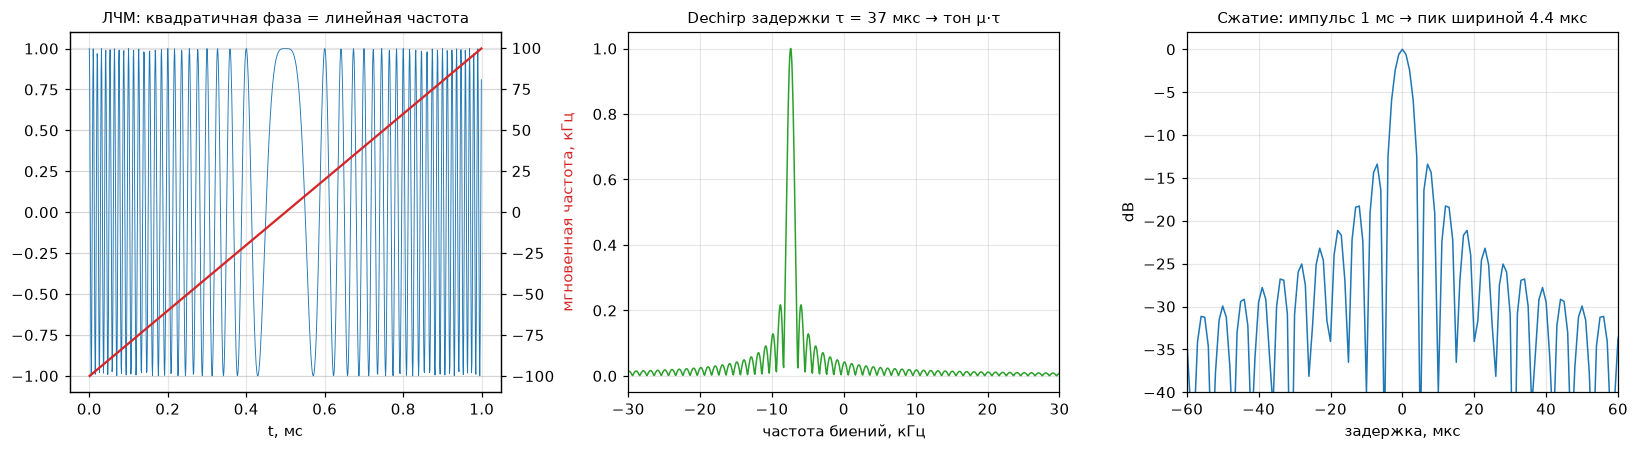

Мгновенная частота от -99.9 до 99.7 кГц: наклон μ = B/T = 200 кГц/мс
Dechirp: частота биений -7.38 кГц → τ̂ = 36.88 мкс (задано 37) — задержка у чирпа превращается в частоту (LoRa, радар, AFDM)
Сжатие импульса: ширина пика по −3 дБ 4.38 мкс (теория 0.886/B = 4.43 мкс); коэффициент сжатия B·T = 200


In [9]:
# ЛЧМ: полоса B за время T, квадратичная фаза
FSc, Tc, Bc = 1e6, 1e-3, 200e3
tc = np.arange(int(FSc * Tc)) / FSc; mu = Bc / Tc
chirp = np.exp(1j * np.pi * mu * (tc - Tc / 2) ** 2)          # φ(t) = π·μ·t² → f(t) = μ·t
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].plot(tc * 1e3, chirp.real, "C0", lw=0.6)
a2 = ax[0].twinx(); fi = np.diff(np.unwrap(np.angle(chirp))) * FSc / (2 * np.pi)
a2.plot(tc[1:] * 1e3, fi / 1e3, "C3", lw=1.5); a2.set_ylabel("мгновенная частота, кГц", color="C3")
ax[0].set_xlabel("t, мс"); ax[0].set_title("ЛЧМ: квадратичная фаза = линейная частота", fontsize=10)
# dechirp: задержанная копия × сопряжённый эталон = тон с частотой μ·τ
tau = 37e-6
rx = np.exp(1j * np.pi * mu * (tc - Tc / 2 - tau) ** 2)
beat = rx * np.conj(chirp)
F = np.abs(np.fft.fftshift(np.fft.fft(beat, 16 * len(tc)))); fF = np.fft.fftshift(np.fft.fftfreq(16 * len(tc), 1 / FSc))
f_beat = fF[np.argmax(F)]
ax[1].plot(fF / 1e3, F / F.max(), "C2", lw=1); ax[1].set_xlim(-30, 30); ax[1].set_xlabel("частота биений, кГц")
ax[1].set_title(f"Dechirp задержки τ = {tau*1e6:.0f} мкс → тон μ·τ", fontsize=10)
# сжатие импульса: согласованный фильтр сжимает T до ~1/B
mf = np.correlate(np.r_[np.zeros(len(tc)), chirp, np.zeros(len(tc))], chirp, mode="valid")
m = np.abs(mf) / np.abs(mf).max(); tm = (np.arange(len(m)) - len(tc)) / FSc
fine = np.linspace(tm[0], tm[-1], 200 * len(tm)); mi = np.interp(fine, tm, m); w3 = np.ptp(fine[mi >= 1 / np.sqrt(2)])
ax[2].plot(tm * 1e6, 20 * np.log10(m + 1e-6), "C0", lw=1); ax[2].set_xlim(-60, 60); ax[2].set_ylim(-40, 2)
ax[2].set_xlabel("задержка, мкс"); ax[2].set_ylabel("dB")
ax[2].set_title(f"Сжатие: импульс {Tc*1e3:.0f} мс → пик шириной {w3*1e6:.1f} мкс", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Мгновенная частота от {fi[0]/1e3:.1f} до {fi[-1]/1e3:.1f} кГц: наклон μ = B/T = {mu/1e6:.0f} кГц/мс")
print(f"Dechirp: частота биений {f_beat/1e3:.2f} кГц → τ̂ = {abs(f_beat)/mu*1e6:.2f} мкс (задано {tau*1e6:.0f}) — задержка у чирпа превращается в частоту (LoRa, радар, AFDM)")
print(f"Сжатие импульса: ширина пика по −3 дБ {w3*1e6:.2f} мкс (теория 0.886/B = {0.886/Bc*1e6:.2f} мкс); коэффициент сжатия B·T = {Bc*Tc:.0f}")

## 8. Канал
* **Многолучевость** — сигнал приходит несколькими путями (отражения от зданий, земли) с разными задержками и фазами: $h(\tau)=\sum_pa_p\delta(\tau-\tau_p)$. На частоте лучи то складываются, то вычитаются: **провалы** в $|H(f)|$ через $1/\Delta\tau$.
* **Профиль задержек (PDP), разброс задержек** $\tau_{rms}$ — средняя мощность лучей по задержке и её среднеквадратичная ширина. EPA/EVA/ETU в `lte_sim` — стандартные профили 3GPP.
* **Когерентная полоса** $B_c\sim1/(2\pi\tau_{rms})$ — на каком разносе частот канал «помнит» себя (корреляция падает до 0.5). Если полоса сигнала много меньше $B_c$, замирания **плоские** (весь сигнал проваливается целиком); если больше — **частотно-селективные** (провалы внутри полосы, ISI).
* **Доплер** $f_D=vf_c/c$ — сдвиг частоты от движения. Лучи с разных направлений получают разные сдвиги — **доплеровское рассеяние** (спектр Джейкса). **Время когерентности** $T_c\approx0.423/f_D$ — как долго канал постоянен. Быстрые замирания — канал меняется за символ или кадр; медленные — нет.
* **Рэлей, Райс, K-фактор** — распределение амплитуды $|h|$. Много лучей без прямого → $h$ комплексно-гауссов, $|h|$ по Рэлею, глубокие провалы часты: $P(|h|^2<-20\text{ дБ})=1\%$. Есть прямой луч (**LOS**) с долей мощности $K/(K+1)$ → Райс: при $K=5$ провалы в 20 раз реже (`ocusync_sim`, канал «воздух–земля»).
* **Потери на трассе** — в свободном пространстве $20\lg(4\pi d/\lambda)$: +6 дБ на каждое удвоение расстояния. **Бюджет линии** — мощность передатчика + усиления антенн − потери − требуемый SNR = запас.
* **Двойная дисперсия** — канал рассеивает и по задержке, и по доплеру одновременно (скоростные поезда, спутники, дроны). На этом построены `otfs_sim` и вся DD-серия (уровень 12).

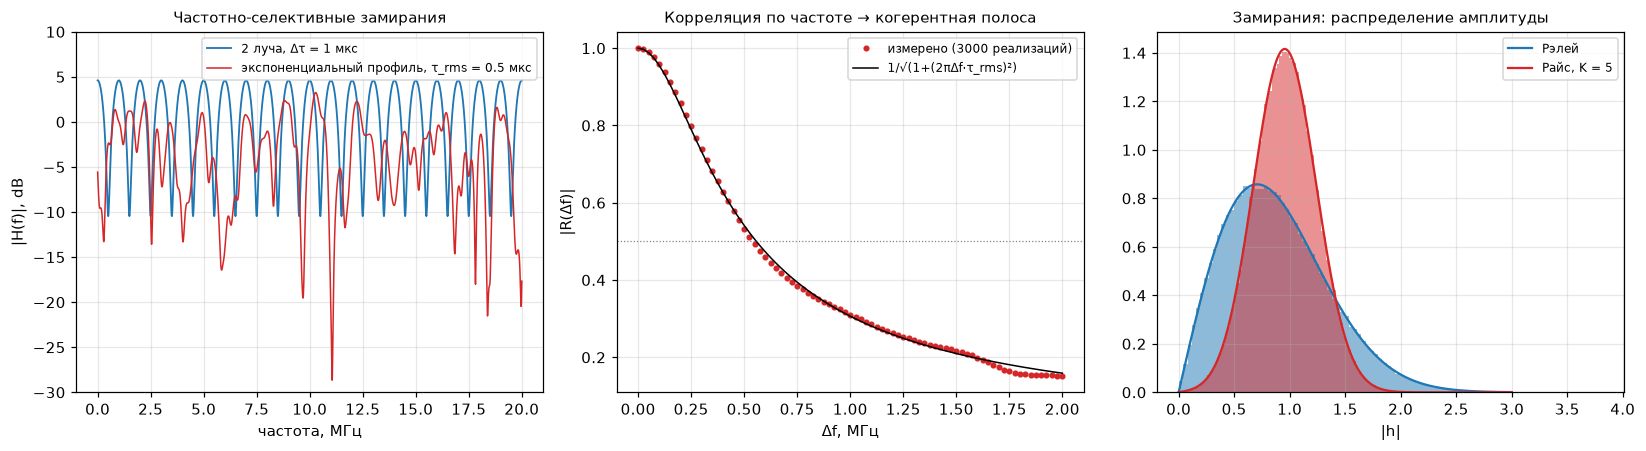

Два луча: провалы через 1/Δτ = 1 МГц, глубина -10.5 дБ
τ_rms = 0.495 мкс; корреляция падает до 0.5 на Δf = 541 кГц (теория √3/(2π·τ_rms) = 557 кГц) — это когерентная полоса
Глубокие провалы (|h|² < −20 дБ): Рэлей 1.01% (теория 1 − e^(−0.01) = 1.00%), Райс K = 5: 0.051%
Доплер: 120 км/ч на 2 ГГц → f_D = v·f_c/c = 222 Гц; корреляция канала во времени: измерено 0.558 при 1.00 мс, теория J₀(2πf_D·Δt) = 0.569; время когерентности ≈ 0.423/f_D = 1.90 мс
Потери в свободном пространстве 20·lg(4πd/λ): 1 км на 2.4 ГГц = 100.0 дБ; удвоение расстояния = +6 дБ


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
# многолучевость: АЧХ двух лучей и экспоненциального профиля
f = np.linspace(0, 20e6, 2001)
H2 = np.abs(1 + 0.7 * np.exp(-2j * np.pi * f * 1e-6))
ax[0].plot(f / 1e6, 20 * np.log10(H2), "C0", lw=1.2, label="2 луча, Δτ = 1 мкс")
TAU = 0.5e-6; dl = np.arange(0, 8 * TAU, 25e-9); pdp = np.exp(-dl / TAU); pdp /= pdp.sum()
hh = crandn(len(dl), rng) * np.sqrt(pdp)
Hm = np.abs(np.exp(-2j * np.pi * np.outer(f, dl)) @ hh)
ax[0].plot(f / 1e6, 20 * np.log10(Hm), "C3", lw=1, label=f"экспоненциальный профиль, τ_rms = {TAU*1e6:.1f} мкс")
ax[0].set_ylim(-30, 10); ax[0].set_xlabel("частота, МГц"); ax[0].set_ylabel("|H(f)|, dB"); ax[0].legend(fontsize=8)
ax[0].set_title("Частотно-селективные замирания", fontsize=10)
# когерентная полоса
dfs = np.linspace(0, 2e6, 81); R = np.zeros(len(dfs), complex)
for _ in range(3000):
    hh = crandn(len(dl), rng) * np.sqrt(pdp)
    H0 = np.exp(-2j * np.pi * np.outer(dfs, dl)) @ hh
    R += H0 * np.conj(H0[0])
R = np.abs(R) / np.abs(R[0])
tr = np.sqrt(np.sum(pdp * dl ** 2) - np.sum(pdp * dl) ** 2)
R_th = 1 / np.sqrt(1 + (2 * np.pi * dfs * tr) ** 2)
ax[1].plot(dfs / 1e6, R, "C3o", ms=3, label="измерено (3000 реализаций)"); ax[1].plot(dfs / 1e6, R_th, "k-", lw=1, label="1/√(1+(2πΔf·τ_rms)²)")
ax[1].axhline(0.5, color="gray", ls=":", lw=0.8); ax[1].set_xlabel("Δf, МГц"); ax[1].set_ylabel("|R(Δf)|"); ax[1].legend(fontsize=8)
ax[1].set_title("Корреляция по частоте → когерентная полоса", fontsize=10)
# распределение огибающей: Рэлей (нет прямой видимости) и Райс (K = 5)
nsamp = 200000; K = 5
ray = np.abs(crandn(nsamp, rng))
ric = np.abs(np.sqrt(K / (K + 1)) + crandn(nsamp, rng) * np.sqrt(1 / (K + 1)))
r = np.linspace(0, 3, 300)
ax[2].hist(ray, 100, density=True, alpha=0.5, color="C0"); ax[2].plot(r, 2 * r * np.exp(-r ** 2), "C0", lw=1.5, label="Рэлей")
sR = np.sqrt(1 / (2 * (K + 1)))
ax[2].hist(ric, 100, density=True, alpha=0.5, color="C3"); ax[2].plot(r, rice.pdf(r, np.sqrt(K / (K + 1)) / sR, scale=sR), "C3", lw=1.5, label=f"Райс, K = {K}")
ax[2].set_xlabel("|h|"); ax[2].legend(fontsize=8); ax[2].set_title("Замирания: распределение амплитуды", fontsize=10)
plt.tight_layout(); plt.show()

dfi = np.linspace(0, 2e6, 20001); Ri = np.interp(dfi, dfs, R); f_half = dfi[np.argmax(Ri < 0.5)]
print(f"Два луча: провалы через 1/Δτ = {1/1e-6/1e6:.0f} МГц, глубина {20*np.log10(1-0.7):.1f} дБ")
print(f"τ_rms = {tr*1e6:.3f} мкс; корреляция падает до 0.5 на Δf = {f_half/1e3:.0f} кГц (теория √3/(2π·τ_rms) = {np.sqrt(3)/(2*np.pi*tr)/1e3:.0f} кГц) — это когерентная полоса")
print(f"Глубокие провалы (|h|² < −20 дБ): Рэлей {np.mean(ray**2 < 0.01):.2%} (теория 1 − e^(−0.01) = {1-np.exp(-0.01):.2%}), Райс K = 5: {np.mean(ric**2 < 0.01):.3%}")

# доплер и время когерентности
v, fc = 120 / 3.6, 2e9; fD = v * fc / 3e8
lags = np.linspace(0, 3e-3, 61); Kc = 32; acc = np.zeros(len(lags), complex)
for _ in range(3000):
    th = rng.uniform(0, 2 * np.pi, Kc); ph = rng.uniform(0, 2 * np.pi, Kc)
    g = np.exp(1j * (2 * np.pi * fD * np.cos(th)[None] * lags[:, None] + ph[None])).sum(1) / np.sqrt(Kc)
    acc += g * np.conj(g[0])
acc = (acc / 3000).real
print(f"Доплер: 120 км/ч на 2 ГГц → f_D = v·f_c/c = {fD:.0f} Гц; корреляция канала во времени: измерено {acc[20]:.3f} при {lags[20]*1e3:.2f} мс, теория J₀(2πf_D·Δt) = {j0(2*np.pi*fD*lags[20]):.3f}; время когерентности ≈ 0.423/f_D = {0.423/fD*1e3:.2f} мс")
print(f"Потери в свободном пространстве 20·lg(4πd/λ): 1 км на 2.4 ГГц = {20*np.log10(4*np.pi*1e3/(3e8/2.4e9)):.1f} дБ; удвоение расстояния = +6 дБ")

## 9. Борьба с каналом
* **Оценка канала, пилот** — известные символы (**пилоты**, CRS в LTE, DMRS в NR, ZC в DroneID), по которым приёмник измеряет $H$. **LS-оценка** $\hat H=Y/X_{пилот}$ шумна, её сглаживают (интерполяция, DFT-сглаживание, `ocusync_sim` раздел 5).
* **Эквалайзер** — снимает действие канала. **ZF** (zero forcing) $\hat X=Y/H$ — точная инверсия, но в провале делит шум на маленькое $|h|$ и раздувает его. **MMSE** $\hat X=\frac{H^*Y}{|H|^2+1/\mathrm{SNR}}$ — компромисс между остаточной помехой и шумом. **LMMSE** — то же для матричного канала, когда символы смешаны (`otfs_sim`, `ocdm_sim`).
* **Разнесение** — передать одну информацию через независимо замирающие копии: по времени (перемежение + код), по частоте (код поверх поднесущих), в пространстве (несколько антенн), по многолучёвости (RAKE, OTFS). Вероятность, что **все** копии в провале, падает как $\mathrm{SNR}^{-L}$. **Порядок разнесения** $L$ — наклон кривой BER: $L$ декад на 10 дБ.
* **MRC** (maximum ratio combining) — оптимальное сложение копий: каждая с весом $h_\ell^*$, сильные ветви учитываются больше.
* **Перемежитель** — перестановка бит, чтобы пакет ошибок от одного провала разошёлся по разным кодовым словам (`turbo_sim` раздел 11, `lte_sim`).

Цена замираний без разнесения: для BER $10^{-5}$ нужно ~44 дБ вместо 9.6 дБ в AWGN. Две ветви сокращают это до ~21 дБ на ветвь, четыре — до ~10 дБ.

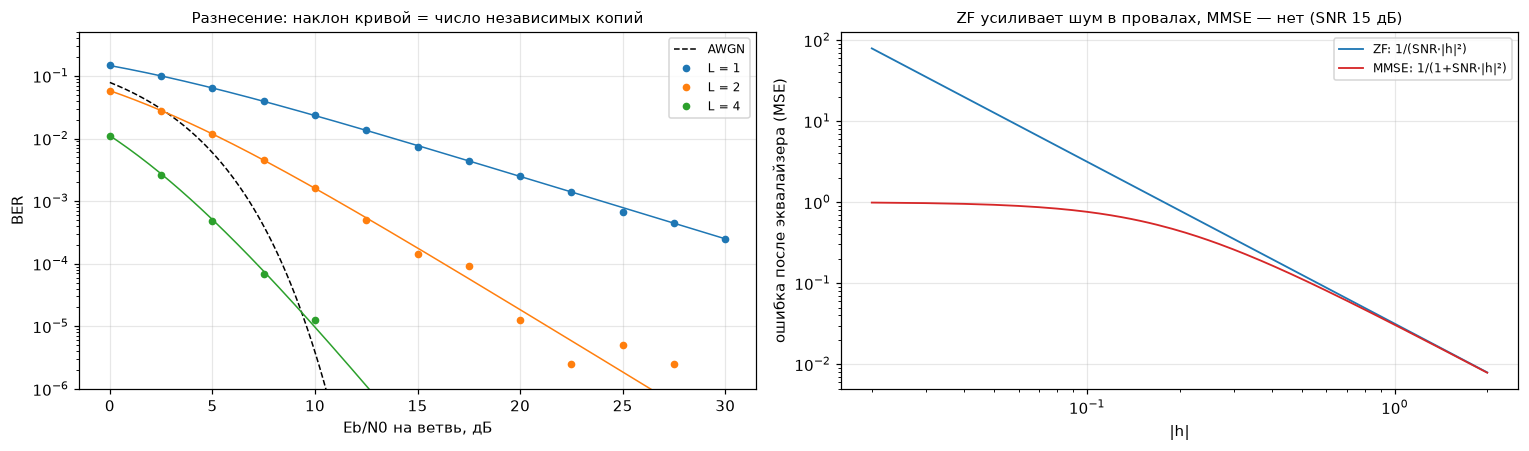

  L = 1: BER при 10 дБ измерено 2.38e-02, теория 2.33e-02; наклон 20→30 дБ: 1.00 декады на 10 дБ
  L = 2: BER при 10 дБ измерено 1.60e-03, теория 1.60e-03; наклон 20→30 дБ: 1.99 декады на 10 дБ
  L = 4: BER при 10 дБ измерено 1.25e-05, теория 9.70e-06; наклон 20→30 дБ: 3.99 декады на 10 дБ
Без разнесения для BER 1e-5 нужно ~44 дБ (≈ 1/(4·Eb/N0)), в AWGN — 9.6 дБ: замирания стоят ~35 дБ


In [11]:
# разнесение: BPSK в замираниях Рэлея с L ветвями и сложением MRC
ebn0 = np.arange(0, 31, 2.5)
def ber_mrc_th(L, g):
    m = np.sqrt(g / (1 + g)); return ((1 - m) / 2) ** L * sum(comb(L - 1 + k, k) * ((1 + m) / 2) ** k for k in range(L))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
eb = np.linspace(0, 30, 300); g = 10 ** (eb / 10)
ax[0].semilogy(eb, Q(np.sqrt(2 * g)), "k--", lw=1, label="AWGN")
meas = {}
for L, c in ((1, "C0"), (2, "C1"), (4, "C2")):
    ax[0].semilogy(eb, ber_mrc_th(L, g), c, lw=1)
    bm = []
    for e in ebn0:
        nb = 400000; b = rng.integers(0, 2, nb); x = 1 - 2 * b
        h = crandn((L, nb), rng); n = crandn((L, nb), rng) * np.sqrt(1 / (2 * 10 ** (e / 10)) * 2)
        z = np.sum(np.conj(h) * (h * x + n), 0).real                  # MRC
        bm.append(np.mean((z < 0) != b))
    meas[L] = np.array(bm)
    ax[0].semilogy(ebn0, np.maximum(bm, 1e-7), c + "o", ms=4, label=f"L = {L}")
ax[0].set_ylim(1e-6, 0.5); ax[0].set_xlabel("Eb/N0 на ветвь, дБ"); ax[0].set_ylabel("BER"); ax[0].legend(fontsize=8)
ax[0].set_title("Разнесение: наклон кривой = число независимых копий", fontsize=10)
# эквалайзер: ZF против MMSE на одной поднесущей в провале
snr = 10 ** (15 / 10); hk = np.linspace(0.02, 2, 200)
mse_zf = 1 / (snr * hk ** 2); mse_mmse = 1 / (1 + snr * hk ** 2)
ax[1].loglog(hk, mse_zf, "C0", lw=1.2, label="ZF: 1/(SNR·|h|²)"); ax[1].loglog(hk, mse_mmse, "C3", lw=1.2, label="MMSE: 1/(1+SNR·|h|²)")
ax[1].set_xlabel("|h|"); ax[1].set_ylabel("ошибка после эквалайзера (MSE)"); ax[1].legend(fontsize=8)
ax[1].set_title("ZF усиливает шум в провалах, MMSE — нет (SNR 15 дБ)", fontsize=10)
plt.tight_layout(); plt.show()
i10 = list(ebn0).index(10)
for L in (1, 2, 4):
    sl = np.log10(ber_mrc_th(L, 10 ** 2) / ber_mrc_th(L, 10 ** 3))
    print(f"  L = {L}: BER при 10 дБ измерено {meas[L][i10]:.2e}, теория {ber_mrc_th(L, 10):.2e}; наклон 20→30 дБ: {sl:.2f} декады на 10 дБ")
print(f"Без разнесения для BER 1e-5 нужно ~{10*np.log10(1/(4*1e-5)):.0f} дБ (≈ 1/(4·Eb/N0)), в AWGN — 9.6 дБ: замирания стоят ~35 дБ")

## 10. Многочастотная передача
* **OFDM, поднесущая, разнос** $\Delta f$ — полоса делится на $N$ узких **поднесущих**, на каждой свой символ QAM; модулятор — IFFT, демодулятор — FFT. Поднесущая уже когерентной полосы → на ней канал плоский, эквалайзер — одно деление (`ofdm_sim`, `lte_sim`).
* **Циклический префикс (CP)** — копия конца символа перед его началом. Пока задержки канала короче CP, линейная свёртка с каналом становится **круговой**, и FFT диагонализует её точно: $Y_k=H_kX_k$ (проверка: ошибка $10^{-15}$; без CP — ~0.2).
* **ICI** (inter-carrier interference) — утечка между поднесущими, когда ортогональность нарушена: сдвигом частоты, доплером, фазовым шумом, окном не в CP.
* **CFO, STO** — сдвиг несущей частоты и ошибка момента начала символа; их оценивает **синхронизация** (`ofdm_sim` раздел 3, `ocusync_sim` раздел 3).
* **Ресурсная сетка, ресурсный элемент, OFDMA** — сетка «время × поднесущая»; разные пользователи получают разные клетки.
* **Пик-фактор (PAPR), CCDF** — отношение пиковой мгновенной мощности к средней. Сумма многих независимых поднесущих почти гауссова: пики 9–10 дБ против ~4 дБ у одной несущей. **CCDF** — вероятность превышения порога. Пики заставляют усилитель работать с запасом (**IBO**) и низким КПД (`ofdm_sim` раздел 5).
* **SC-FDMA, SC-FDE** — одна несущая с тем же CP и частотным эквалайзером: пик-фактор как у одной несущей (аплинк LTE, OCDM ≡ SC-FDE в `ocdm_sim`).
* **Нумерология** — выбор $\Delta f$ и CP под канал: $\Delta f=15\cdot2^\mu$ кГц в 5G NR (`ofdm_sim` раздел 7).

С CP: max|Y − H·X| = 1.4e-15; без CP: 0.23 — межсимвольная помеха и потеря ортогональности (ICI)


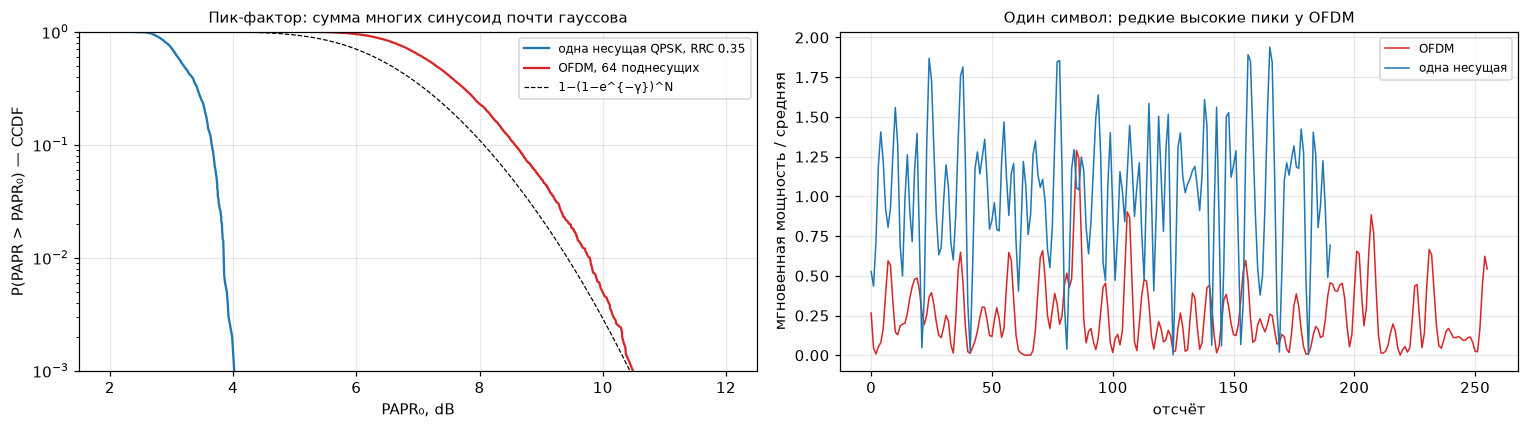

PAPR, превышаемый в 1 % символов: одна несущая 3.8 дБ, OFDM 9.8 дБ (теория по Найквисту 9.4 дБ)


In [12]:
# CP превращает линейную свёртку в круговую → Y = H·X поэлементно
Nf, Ncp = 64, 8
X = (1 - 2 * rng.integers(0, 2, Nf)) + 1j * (1 - 2 * rng.integers(0, 2, Nf))
x = np.fft.ifft(X); tx = np.r_[x[-Ncp:], x]
h = crandn(6, rng) * np.exp(-np.arange(6) / 2)
rx = np.convolve(tx, h)[Ncp:Ncp + Nf]
Y = np.fft.fft(rx); H = np.fft.fft(h, Nf)
rx_nocp = np.convolve(x, h)[:Nf]
print(f"С CP: max|Y − H·X| = {np.abs(Y - H*X).max():.1e}; без CP: {np.abs(np.fft.fft(rx_nocp) - H*X).max():.2f} — межсимвольная помеха и потеря ортогональности (ICI)")

# пик-фактор: одна несущая против OFDM
def papr(x): return 10 * np.log10(np.max(np.abs(x) ** 2, -1) / np.mean(np.abs(x) ** 2, -1))
S, N, OSf = 5000, 64, 4
qp = ((1 - 2 * rng.integers(0, 2, (S, N))) + 1j * (1 - 2 * rng.integers(0, 2, (S, N)))) / np.sqrt(2)
G = np.zeros((S, N * OSf), complex); G[:, :N // 2] = qp[:, :N // 2]; G[:, -N // 2:] = qp[:, N // 2:]
p_ofdm = papr(np.fft.ifft(G, axis=1))
SPS = 4; up = np.zeros((S, N * SPS), complex); up[:, ::SPS] = qp; hr = rrc(0.35, SPS, 8)
sc = np.array([np.convolve(r, hr)[len(hr):len(hr) + N * SPS - len(hr)] for r in up[:1000]])
p_sc = papr(sc)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for p, nm, c in ((p_sc, "одна несущая QPSK, RRC 0.35", "C0"), (p_ofdm, "OFDM, 64 поднесущих", "C3")):
    ps = np.sort(p); ax[0].semilogy(ps, 1 - np.arange(len(ps)) / len(ps), c, lw=1.5, label=nm)
gg = np.linspace(2, 12, 200); ax[0].semilogy(gg, 1 - (1 - np.exp(-10 ** (gg / 10))) ** N, "k--", lw=0.8, label="1−(1−e^{−γ})^N")
ax[0].set_ylim(1e-3, 1); ax[0].set_xlabel("PAPR₀, dB"); ax[0].set_ylabel("P(PAPR > PAPR₀) — CCDF"); ax[0].legend(fontsize=8)
ax[0].set_title("Пик-фактор: сумма многих синусоид почти гауссова", fontsize=10)
xo = np.fft.ifft(G[0]) * np.sqrt(N * OSf); ax[1].plot(np.abs(xo) ** 2, "C3", lw=1, label="OFDM")
ax[1].plot(np.abs(sc[0] / np.sqrt(np.mean(np.abs(sc[0]) ** 2))) ** 2, "C0", lw=1, label="одна несущая")
ax[1].set_xlabel("отсчёт"); ax[1].set_ylabel("мгновенная мощность / средняя"); ax[1].legend(fontsize=8)
ax[1].set_title("Один символ: редкие высокие пики у OFDM", fontsize=10)
plt.tight_layout(); plt.show()
print(f"PAPR, превышаемый в 1 % символов: одна несущая {np.quantile(p_sc, 0.99):.1f} дБ, OFDM {np.quantile(p_ofdm, 0.99):.1f} дБ (теория по Найквисту {gg[np.argmin(np.abs(1-(1-np.exp(-10**(gg/10)))**N - 0.01))]:.1f} дБ)")

## 11. Помехоустойчивое кодирование
* **Канальный код, избыточность, скорость** $R=k/n$ — к $k$ битам данных добавляются $n-k$ проверочных; передаётся **кодовое слово** длины $n$.
* **Проверка чётности, синдром** — проверки $Hc^T=0$ (матрица $H$). Если приём нарушил проверки, **синдром** $s=Hr^T\neq0$ указывает на ошибку; у кода Хэмминга (7,4) — прямо на её позицию.
* **Расстояние Хэмминга** $d_{min}$ — минимальное число различающихся бит между кодовыми словами; код исправляет $\lfloor(d-1)/2\rfloor$ ошибок. У (7,4) $d=3$.
* **CRC** — код только для **обнаружения** ошибок в кадре (решение «принять / запросить повтор», HARQ).
* **Кодовый выигрыш** — на сколько дБ меньше $E_b/N_0$ нужно с кодом при той же BER. Хэмминг (7,4): ~1 дБ с жёстким решением, ~2.5 дБ с мягким (уровень 4) — мягкое решение почти всегда стоит ~2 дБ.
* **Итеративное декодирование, внешняя информация (экстринсик)** — декодеры или узлы графа многократно обмениваются LLR, передавая только *новое* знание (`ldpc_sim` разделы 6–8, `turbo_sim` раздел 6).
* **Водопад, пол ошибок, порог** — кривая BER современного кода круто падает после **порога** (водопад) и может выйти на **пол** из-за слабых конфигураций кода. Порог предсказывают **EXIT-диаграмма** и **плотностная эволюция**.
* **LDPC, турбокод** — коды, работающие в ~1 дБ от Шеннона: разреженная матрица проверок с BP-декодером (`ldpc_sim`), два свёрточных кода с перемежителем (`turbo_sim`).
* **Согласование скорости (rate matching)** — выкалывание или повтор кодовых бит под размер ресурса (`ocusync_sim` раздел 6).

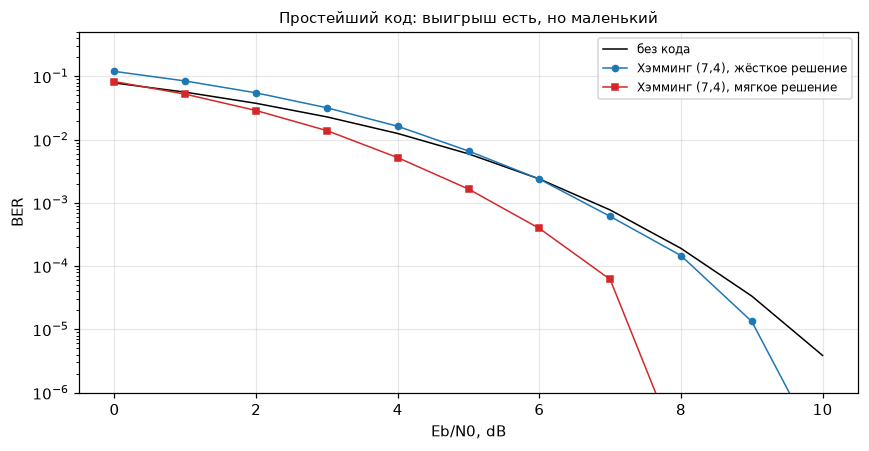

Минимальное расстояние Хэмминга: 3 (исправляет ⌊(d−1)/2⌋ = 1 ошибку); скорость R = 4/7 = 0.57
Eb/N0 для BER 1e-4: без кода 9.2 дБ, жёсткое 8.2 дБ, мягкое 6.7 дБ → кодовый выигрыш 1.1 и 2.5 дБ
Для сравнения: турбокод LTE и LDPC (turbo_sim, ldpc_sim) дают при BER 1e-4 выигрыш ~7–8 дБ и подходят к Шеннону на ~1 дБ


In [13]:
# код Хэмминга (7,4): 4 бита данных + 3 проверки чётности, исправляет одну ошибку
Gm = np.array([[1, 0, 0, 0, 1, 1, 0], [0, 1, 0, 0, 1, 0, 1], [0, 0, 1, 0, 0, 1, 1], [0, 0, 0, 1, 1, 1, 1]])
Hm = np.array([[1, 1, 0, 1, 1, 0, 0], [1, 0, 1, 1, 0, 1, 0], [0, 1, 1, 1, 0, 0, 1]])
assert not (Gm @ Hm.T % 2).any()
syn2pos = {tuple(Hm[:, j]): j for j in range(7)}
CW = np.array([[int(b) for b in format(m, "04b")] for m in range(16)]) @ Gm % 2     # все 16 кодовых слов
dH = min(np.sum(a != b) for i, a in enumerate(CW) for b in CW[i + 1:])
ebn0 = np.arange(0, 11)
ber_unc, ber_hard, ber_soft = [], [], []
for e in ebn0:
    nw = 150000; m = rng.integers(0, 2, (nw, 4)); c = m @ Gm % 2
    sig = np.sqrt(1 / (2 * (4 / 7) * 10 ** (e / 10)))                  # энергия на бит данных: на кодовый бит R·Eb
    y = (1 - 2 * c) + rng.standard_normal(c.shape) * sig
    hd = (y < 0).astype(int); s = hd @ Hm.T % 2
    for i in np.where(s.any(1))[0]:
        hd[i, syn2pos[tuple(s[i])]] ^= 1                               # синдром указывает позицию ошибки
    ber_hard.append(np.mean(hd[:, :4] != m))
    corr = y @ (1 - 2 * CW).T; best = CW[np.argmax(corr, 1)]          # мягкое решение: ближайшее кодовое слово по евклиду
    ber_soft.append(np.mean(best[:, :4] != m))
g = 10 ** (ebn0 / 10)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.semilogy(ebn0, Q(np.sqrt(2 * g)), "k-", lw=1, label="без кода")
ax.semilogy(ebn0, np.maximum(ber_hard, 1e-7), "C0o-", ms=4, lw=1, label="Хэмминг (7,4), жёсткое решение")
ax.semilogy(ebn0, np.maximum(ber_soft, 1e-7), "C3s-", ms=4, lw=1, label="Хэмминг (7,4), мягкое решение")
ax.set_ylim(1e-6, 0.5); ax.set_xlabel("Eb/N0, dB"); ax.set_ylabel("BER"); ax.legend(fontsize=8)
ax.set_title("Простейший код: выигрыш есть, но маленький", fontsize=10)
plt.tight_layout(); plt.show()
def need(b):
    b = np.array(b); i = np.argmax(b < 1e-4)
    return ebn0[i - 1] + (np.log10(b[i - 1]) + 4) / (np.log10(b[i - 1]) - np.log10(b[i])) if i > 0 else np.nan
eb_unc = 10 * np.log10(8.4)
print(f"Минимальное расстояние Хэмминга: {dH} (исправляет ⌊(d−1)/2⌋ = {(dH-1)//2} ошибку); скорость R = 4/7 = {4/7:.2f}")
print(f"Eb/N0 для BER 1e-4: без кода {eb_unc:.1f} дБ, жёсткое {need(ber_hard):.1f} дБ, мягкое {need(ber_soft):.1f} дБ → кодовый выигрыш {eb_unc-need(ber_hard):.1f} и {eb_unc-need(ber_soft):.1f} дБ")
print("Для сравнения: турбокод LTE и LDPC (turbo_sim, ldpc_sim) дают при BER 1e-4 выигрыш ~7–8 дБ и подходят к Шеннону на ~1 дБ")

## 12. Область задержка–доплер
* **Функция рассеяния, DD-представление канала** — канал как набор точек $(\tau_p,\nu_p)$ с усилениями $h_p$: $h(\tau,\nu)=\sum_ph_p\delta(\tau-\tau_p)\delta(\nu-\nu_p)$. Получается из частотно-временного отклика $H(t,f)$ двумерным преобразованием Фурье (**симплектическое**: по времени → доплер, по частоте → задержка).
* **Почему это удобно** — во времени–частоте канал «кипит»: провалы везде и меняются с каждым символом (слева). В задержке–доплере те же три луча — **три неподвижные точки** (справа, 100 % энергии в 3 клетках из 2048). Канал **разрежен** и **почти постоянен** — его можно оценить одним пилотом.
* **OTFS, ISFFT** — модуляция, кладущая символы прямо на сетку задержка–доплер; переход к OFDM-сетке — ISFFT (`otfs_sim`). Каждый символ видит **все** лучи — полное разнесение.
* **Дробный доплер, ядро Дирихле** — если доплер не попадает в бин, точка растекается по доплеру (здесь в главной клетке 57 % энергии). Главная практическая трудность OTFS: пол оценки канала (`otfs_sim` раздел 3).
* **Преобразование Зака, квазипериодичность** — непрерывная основа DD-представления; с гауссовым окном канал предсказуем по одному пилоту (`zak_sim`).
* **Встроенный пилот, защитная зона** — пилот-импульс в DD-сетке, окружённый нулями размером с разброс канала (`otfs_sim` раздел 5, `afdm_sim` раздел 5).
* **Детектор передачи сообщений (MP)** — итеративный детектор, использующий разреженность DD-канала вместо обращения матрицы (`otfs_sim` раздел 6).

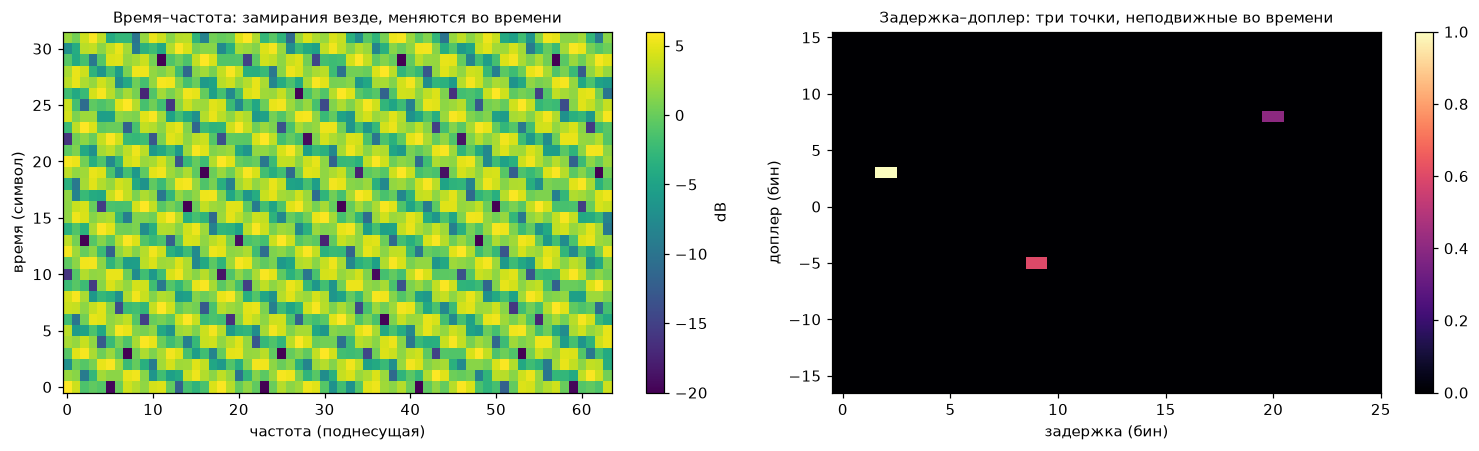

В области задержка–доплер 3 клетки из 2048 несут 100.0% энергии; в области время–частота |H| меняется от 0.00 до 2.00
Дробный доплер 3.4 бина: в самой большой клетке 57.3% энергии, остальное растекается по доплеру по ядру Дирихле (otfs_sim, раздел 3)


In [14]:
# один и тот же канал из трёх лучей в двух описаниях: время–частота и задержка–доплер
M, Nd = 64, 32                                                # бины задержки × бины доплера
paths = [(1.0, 2, 3), (0.6, 9, -5), (0.4, 20, 8)]              # (усиление, задержка, доплер) в бинах
n = np.arange(Nd); k = np.arange(M)
H_tf = sum(a * np.exp(-2j * np.pi * k[None] * l / M) * np.exp(2j * np.pi * n[:, None] * v / Nd) for a, l, v in paths)   # H[время n, частота k]
S_dd = np.fft.fft(np.fft.ifft(H_tf, axis=1), axis=0) / Nd       # симплектическое преобразование: → (доплер, задержка)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
im = ax[0].imshow(20 * np.log10(np.abs(H_tf) + 1e-3), aspect="auto", origin="lower", cmap="viridis", vmin=-20, vmax=6); ax[0].grid(False)
ax[0].set_xlabel("частота (поднесущая)"); ax[0].set_ylabel("время (символ)"); plt.colorbar(im, ax=ax[0], label="dB")
ax[0].set_title("Время–частота: замирания везде, меняются во времени", fontsize=10)
im = ax[1].imshow(np.abs(np.fft.fftshift(S_dd, axes=0)), aspect="auto", origin="lower", cmap="magma", extent=[-0.5, M - 0.5, -Nd / 2 - 0.5, Nd / 2 - 0.5]); ax[1].grid(False)
ax[1].set_xlim(-0.5, 25); ax[1].set_xlabel("задержка (бин)"); ax[1].set_ylabel("доплер (бин)"); plt.colorbar(im, ax=ax[1])
ax[1].set_title("Задержка–доплер: три точки, неподвижные во времени", fontsize=10)
plt.tight_layout(); plt.show()
e = np.sort(np.abs(S_dd.ravel()) ** 2)[::-1]
print(f"В области задержка–доплер 3 клетки из {M*Nd} несут {e[:3].sum()/e.sum():.1%} энергии; в области время–частота |H| меняется от {np.abs(H_tf).min():.2f} до {np.abs(H_tf).max():.2f}")
p2 = [(1.0, 2, 3.4)]
H2 = sum(a * np.exp(-2j * np.pi * k[None] * l / M) * np.exp(2j * np.pi * n[:, None] * v / Nd) for a, l, v in p2)
S2 = np.abs(np.fft.fft(np.fft.ifft(H2, axis=1), axis=0) / Nd) ** 2
print(f"Дробный доплер 3.4 бина: в самой большой клетке {S2.max()/S2.sum():.1%} энергии, остальное растекается по доплеру по ядру Дирихле (otfs_sim, раздел 3)")

## Указатель терминов

| термин | англ. | ур. | где подробно |
|---|---|---|---|
| ACLR, внеполосное излучение | ACLR, out-of-band emission | 2 | `ofdm_sim` |
| AWGN | AWGN | 3 | все |
| BER / SER / BLER | bit/symbol/block error rate | 3 | все |
| CFO, синхронизация | carrier frequency offset | 10 | `ofdm_sim`, `ocusync_sim`, `lora_sim` |
| CRC | cyclic redundancy check | 11 | `ocusync_sim` |
| Eb/N0, Es/N0 | — | 3 | `ldpc_sim`, `turbo_sim`, `lte_sim` |
| EVM | error vector magnitude | 3 | `ofdm_sim` |
| EXIT-диаграмма | EXIT chart | 11 | `ldpc_sim`, `turbo_sim` |
| I/Q, комплексная огибающая | complex baseband | 1 | все |
| LLR | log-likelihood ratio | 4 | `ldpc_sim`, `turbo_sim`, `lte_sim` |
| MRC | maximum ratio combining | 9 | `ocusync_sim`, `lte_sim` |
| OFDM, поднесущая | OFDM, subcarrier | 10 | `ofdm_sim`, `lte_sim`, `ocusync_sim` |
| SNR | signal-to-noise ratio | 3 | все |
| ZF / MMSE / LMMSE | equalizers | 9 | `lte_sim`, `otfs_sim`, `ocdm_sim`, `afdm_sim` |
| базис | basis | 6 | `transforms_sim`, `ocdm_sim`, `otsm_sim` |
| вейвлет | wavelet | — | `transforms_sim` |
| водопад, порог, пол ошибок | waterfall, threshold, error floor | 11 | `ldpc_sim`, `turbo_sim` |
| выигрыш обработки | processing gain | 6 | `cdma_sim`, `lora_sim` |
| глазковая диаграмма | eye diagram | 5 | — |
| двойная дисперсия | doubly dispersive channel | 8 | `otfs_sim`, `zak_sim`, `afdm_sim` |
| дробный доплер | fractional Doppler | 12 | `otfs_sim`, `zak_sim`, `afdm_sim` |
| доплер, время когерентности | Doppler, coherence time | 8 | `lte_sim`, `otfs_sim`, `ofdm_sim` |
| задержка–доплер (DD) | delay–Doppler | 12 | `otfs_sim`, `zak_sim`, `otsm_sim` |
| Задов–Чу, CAZAC | Zadoff–Chu | 6 | `ocusync_sim`, `lte_sim` |
| замирания Рэлея / Райса, K-фактор | Rayleigh / Rician fading | 8 | `lte_sim`, `ocusync_sim` |
| итеративное декодирование, экстринсик | iterative decoding, extrinsic | 11 | `ldpc_sim`, `turbo_sim` |
| квадратичная фаза | quadratic phase | 7 | `lora_sim`, `ocdm_sim`, `afdm_sim`, `transforms_sim` |
| код Грея | Gray code | 4 | `ofdm_sim`, `lte_sim` |
| коды Голда, m-последовательность | Gold codes, m-sequence | 6 | `cdma_sim` |
| когерентная полоса, разброс задержек | coherence bandwidth, delay spread | 8 | `lte_sim`, `ofdm_sim` |
| корреляция | correlation | 6 | `cdma_sim`, `lora_sim`, `ocusync_sim` |
| многолучевость | multipath | 8 | `lte_sim`, `ofdm_sim`, все DD |
| мягкое / жёсткое решение | soft / hard decision | 4 | `ldpc_sim`, `turbo_sim` |
| наложение (алиасинг) | aliasing | 1 | — |
| нумерология | numerology | 10 | `ofdm_sim` |
| ортогональность | orthogonality | 6 | `ofdm_sim`, `cdma_sim`, `otsm_sim` |
| перемежитель | interleaver | 9, 11 | `turbo_sim`, `lte_sim` |
| пик-фактор (PAPR), CCDF | peak-to-average power ratio | 10 | `ofdm_sim`, `lte_sim`, `otfs_sim`, `ocdm_sim` |
| пилот, оценка канала | pilot, channel estimation | 9 | `lte_sim`, `ocusync_sim`, `otfs_sim` |
| преобразование Фурье, FFT | Fourier transform | 2 | `transforms_sim` |
| преобразование Френеля | Fresnel transform | 7 | `transforms_sim`, `ocdm_sim`, `afdm_sim` |
| разнесение | diversity | 9 | `lte_sim`, `otfs_sim` |
| расстояние Хэмминга, синдром | Hamming distance, syndrome | 11 | `ldpc_sim` |
| расширение спектра, чип | spread spectrum, chip | 6 | `cdma_sim`, `lora_sim` |
| RRC, скругление | root raised cosine, roll-off | 5 | `otsm_sim` (ODDM) |
| согласованный фильтр | matched filter | 5 | `cdma_sim`, `lora_sim` |
| созвездие, QAM | constellation, QAM | 4 | `lte_sim`, `ofdm_sim` |
| спектральная эффективность, Шеннон | spectral efficiency, Shannon | 3 | `ofdm_sim`, `ldpc_sim` |
| циклический префикс (CP) | cyclic prefix | 10 | `lte_sim`, `ofdm_sim` |
| чирп, ЛЧМ, dechirp | chirp, dechirp | 7 | `lora_sim`, `ocdm_sim`, `afdm_sim` |

## Порядок чтения серии
1. **Основа**: этот ноутбук → `transforms_sim` (базисы: Фурье, вейвлеты, Френель).
2. **Расширение спектра**: `cdma_sim` (корреляция, коды, выигрыш обработки) → `lora_sim` (чирпы).
3. **Коды**: `ldpc_sim` → `turbo_sim` (LLR, итеративное декодирование, водопад).
4. **Многочастотность**: `ofdm_sim` (общая инженерия OFDM) → `lte_sim` (полная система с каналами 3GPP и турбокодом) → `ocusync_sim` (та же техника в дроне).
5. **Каналы с доплером**: `ocdm_sim` (чирп-базис, SC-FDE) → `otfs_sim` → `zak_sim` → `afdm_sim` → `otsm_sim` (итог серии).

Каждый ноутбук самодостаточен; номера уровней здесь подсказывают, какие понятия нужны для него заранее.